# Projeto Final — Análise Exploratória de um App de Delivery
### DS-PY-018 · Análise Exploratória de Dados

**Contexto:** vocês são o time de dados de um app de delivery de comida que opera em **São Paulo, Rio de Janeiro e Belo Horizonte**. A diretoria vai planejar 2025 e pediu um diagnóstico de 2024 antes da reunião de orçamento. Ela quer entender três frentes:

1. **Operação** — quando os pedidos acontecem, quanto tempo as entregas levam e o que atrasa uma entrega;
2. **Clientes** — quanto gastam, como avaliam e o que derruba a avaliação;
3. **Alavancas** — qual o efeito real dos **cupons** (inclusive da campanha *"Julho de cupons"*) e da **chuva** sobre o negócio.

A base `delivery_pedidos.csv` (8.058 pedidos, 18 colunas) veio direto do sistema, **sem nenhum tratamento**. Ela tem problemas de qualidade — encontrá-los faz parte do trabalho.

> A diretoria não quer tabelas. Quer **5 achados** confiáveis e **3 recomendações** defendidas com dados.

---

**Entregas:**
1. Este notebook **resolvido e executado do início ao fim** (Etapas 1 a 11), sem erros.
2. Um **repositório Git** contendo: o notebook, um `README.md` (use o `modelo_README.md` desta pasta), a pasta `saidas/` com a base limpa e a figura principal.
3. Uma **apresentação de 7 minutos** na última aula (5 achados + 3 recomendações + 1 limitação), seguida de perguntas.

**Regras:**
- Trabalho individual.
- O notebook precisa **rodar do início ao fim** (*Kernel → Restart & Run All*) com o CSV original em `../dados/` (ou no caminho indicado no README).
- **Toda decisão de limpeza é justificada**: o que foi feito, por quê, e quantas linhas foram afetadas. Nunca preencha um faltante "porque sim".
- Toda resposta numérica vem com **uma frase de interpretação**.

**Hipóteses obrigatórias (Etapa 9):**

| # | Hipótese de negócio | Variáveis |
|---|---|---|
| H1 | Em dias de chuva as entregas demoram mais | `chuva` × `tempo_entrega_min` |
| H2 | Pedidos com cupom têm ticket diferente dos pedidos sem cupom | `cupom` × `valor_pedido` |
| H3 | Quanto mais demorada a entrega, pior a avaliação | `tempo_entrega_min` × `avaliacao` |
| H4 | O ticket varia conforme o tipo de cozinha | `tipo_cozinha` × `valor_pedido` |
| H5 | A forma de pagamento depende da cidade (qui-quadrado de independência) | `cidade` × `forma_pagamento` |
| H6 | **Do grupo** — uma hipótese própria, formulada na Etapa 1 | à escolha |

**Prazo e apresentação:** o projeto é apresentado na **última aula do módulo**. Ordem das apresentações ordem alfabetica.

**Critérios de avaliação:** rubrica analítica em [`rubrica_avaliacao.md`](rubrica_avaliacao.md) — uso de DataFrames no Pandas · estatísticas descritivas · sumarização · cálculo de métricas · escolha de visualizações · estilização · validação de hipóteses · granularidade · publicação dos dados · tratamento de dados e reprodutibilidade · comunicação. Leiam a rubrica **antes** de começar: ela diz exatamente o que separa "Proficiente" de "Avançado".

### Dicionário de dados (como o sistema descreve as colunas)

| Coluna | Descrição |
|---|---|
| `pedido_id` | identificador do pedido |
| `data_hora` | data e hora do pedido (`AAAA-MM-DD HH:MM`) |
| `cidade`, `bairro` | local de entrega |
| `restaurante_id` | identificador do restaurante |
| `tipo_cozinha` | Pizza, Japonesa, Hambúrguer, Brasileira, Saudável, Doces |
| `plataforma` | Android, iOS ou Web |
| `forma_pagamento` | Cartão de crédito, Pix, Vale-refeição, Dinheiro |
| `cupom` | se o pedido usou cupom de desconto |
| `cliente_novo` | primeiro pedido do cliente no app |
| `chuva` | choveu na cidade naquele dia |
| `distancia_km` | distância restaurante → cliente |
| `tempo_entrega_min` | minutos entre o pedido e a entrega (o sistema grava `999` quando não há registro) |
| `valor_pedido` | valor dos itens, em R$ (sem a taxa) |
| `taxa_entrega` | taxa de entrega cobrada, em R$ |
| `avaliacao` | nota de 1 a 5 dada pelo cliente (opcional) |
| `pais`, `moeda` | país e moeda da transação |

> ⚠️ O dicionário diz o que a coluna **deveria** conter. A Etapa 2 é sobre descobrir o que ela **de fato** contém.

**Como usar este notebook:** cada etapa tem tarefas numeradas. Células `# Sua solução aqui` são código; células *Sua resposta aqui* são texto (interpretação, decisão ou justificativa). Células de código já preenchidas — como os **checkpoints** ✅ — não devem ser alteradas: se um checkpoint falhar, volte e revise a etapa.

In [72]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [73]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

sns.set_theme(style="whitegrid")
DADOS = "../dados/"

---
## Etapa 1 — Perguntas e hipóteses

> Na aula 6 vimos que a EDA começa **antes** do código: sem pergunta, qualquer gráfico parece interessante.

### Tarefa 1.1
Escrevam **5 perguntas de negócio** que a diretoria faria sobre esta base — pelo menos uma de cada frente (operação, clientes, alavancas). Para cada pergunta, indiquem **qual coluna (ou combinação) responde** e **em que granularidade** (pedido, dia, cidade-dia, mês...).

| # | Frente | Pergunta | Coluna(s) que respondem | Granularidade |
|---|---|---|---|---|
| 1 | Operação | Em que horários e dias da semana se concentra o maior volume de pedidos? | `data_hora` → `hora`, `dia_semana` | pedido → hora × dia da semana; média por **dia** |
| 2 | Operação | Qual o tempo médio de entrega e a taxa de atrasos (> 35 e > 45 min) por cidade? | `tempo_entrega_min`, `cidade` | pedido → cidade |
| 3 | Clientes | Qual o ticket típico (mediano) e o peso no faturamento de cada cozinha? | `valor_pedido`, `tipo_cozinha` | pedido → cozinha |
| 4 | Clientes | A partir de quantos minutos de espera a avaliação cai? | `tempo_entrega_min`, `avaliacao` | pedido → faixas de 5 min |
| 5 | Alavancas | Qual o efeito de chuva e cupons no volume, no ticket e no tempo? | `chuva`, `cupom`, `data`, `cidade`, `valor_pedido`, `tempo_entrega_min` | **cidade-dia** (chuva) e **mês/dia** (cupom) |

### Tarefa 1.2
Para cada hipótese obrigatória (H1–H5 do enunciado) escrevam **H0 e H1 estatísticas** e o **teste que pretendem usar**, justificando pelo tipo das variáveis. Depois formulem a **H6** — algo que vocês genuinamente não sabem a resposta.

H1: Chuva × tempo de entrega
   Hipótese Nula (o que queremos descartar): A chuva não muda o tempo de entrega.
   Hipótese Alternativa (o que queremos provar): A chuva aumenta o tempo de entrega.
   Teste: Teste T (ou Mann-Whitney).
   Justificativa simples: Queremos comparar uma média de tempo (um número) entre dois grupos: dias com chuva e dias sem chuva.
   
H2: Cupom × valor do pedido
   Hipótese Nula: Usar cupom não altera o valor do pedido.
   Hipótese Alternativa: O valor do pedido muda quando tem cupom.Teste: 
   Teste de Mann-Whitney.
   Justificativa simples: Estamos comparando valores financeiros (números) entre dois grupos (com cupom e sem cupom). Esse teste é melhor que o Teste T porque lida bem com pedidos de valores muito altos (outliers).
   
H3: Tempo de entrega × avaliação   
    Hipótese Nula: A demora não afeta a nota.
    Hipótese Alternativa: Quanto maior o tempo, pior a nota.
    Teste: Correlação de Spearman.
    Justificativa simples: Queremos ver se duas coisas sobem ou descem juntas. Como a nota é um ranking fechado de 1 a 5 (e não um número livre), o Spearman é o cálculo ideal.
    
H4: Tipo de cozinha × valor do pedido   
    Hipótese Nula: Todas as cozinhas têm o mesmo valor médio.
    Hipótese Alternativa: O valor muda dependendo do tipo de cozinha.
    Teste: Kruskal-Wallis.
    Justificativa simples: Queremos comparar valores financeiros entre vários grupos de cozinhas, e não apenas dois. Esse teste serve para isso quando os valores são irregulares.
    
H5: Cidade × forma de pagamento   
    Hipótese Nula: O jeito de pagar não depende da cidade.
    Hipótese Alternativa: A forma de pagamento muda dependendo da cidade.
    Teste: Qui-quadrado.
    Justificativa simples: Queremos cruzar duas categorias (cidade e pagamento) para descobrir se a escolha de uma afeta a outra.
    
H6: Cliente novo × uso de cupom (Hipótese criada por você)   
    Hipótese Nula: Clientes novos e antigos usam cupons na mesma proporção.
    Hipótese Alternativa: Clientes novos usam mais (ou menos) cupons que os antigos.
    Teste: Qui-quadrado.
    Justificativa simples: É o teste perfeito para comparar se há relação entre dois grupos de "Sim ou Não" (É cliente novo? Sim/Não vs. Usou cupom? Sim/Não).

---
## Etapa 2 — Carga e inspeção

> Ainda **não** mexa nos dados. Esta etapa é um inventário: o que veio, em que formato e com que problemas.

In [74]:
bruto = pd.read_csv(DADOS + "delivery_pedidos.csv")
bruto.shape

(8058, 18)

### Tarefa 2.1
Mostre as 5 primeiras linhas e o resultado de `info()`. Quantas linhas e colunas? Quanta memória a base ocupa?

A base possui 8.058 linhas (entradas) e 18 colunas.

A base ocupa aproximadamente 1.0 MB (o output do Pandas indica memory usage: 1023.1 KB).

In [75]:
# Mostra as 5 primeiras linhas
display(bruto.head())

# Mostra o resultado de info()
bruto.info()

,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao,pais,moeda
0,500000,2024-01-01 11:21,São Paulo,Tatuapé,R912,Hambúrguer,Android,Pix,Não,False,False,2.68,28,"R$ 44,02",7.40,4.0,Brasil,BRL
1,500001,2024-01-01 20:09,São Paulo,Tatuapé,R760,Hambúrguer,Android,Pix,Sim,False,False,3.28,37,45.54,7.94,5.0,Brasil,BRL
2,500002,2024-01-01 11:20,São Paulo,Santana,R760,Hambúrguer,Android,cartao credito,Não,False,False,3.19,30,92.28,7.86,5.0,Brasil,BRL
3,500003,2024-01-01 22:14,São Paulo,Moema,R338,Saudável,Android,Cartão de crédito,Sim,True,False,2.75,17,39.09,7.46,4.0,Brasil,BRL
4,500004,2024-01-01 12:50,São Paulo,Pinheiros,R169,Hambúrguer,Android,Pix,Não,False,False,1.63,24,74.2,6.46,5.0,Brasil,BRL


<class 'pandas.DataFrame'>
RangeIndex: 8058 entries, 0 to 8057
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pedido_id          8058 non-null   int64  
 1   data_hora          8058 non-null   str    
 2   cidade             8058 non-null   str    
 3   bairro             8058 non-null   str    
 4   restaurante_id     8058 non-null   str    
 5   tipo_cozinha       8058 non-null   str    
 6   plataforma         7905 non-null   str    
 7   forma_pagamento    8058 non-null   str    
 8   cupom              8058 non-null   str    
 9   cliente_novo       8058 non-null   bool   
 10  chuva              8058 non-null   bool   
 11  distancia_km       7743 non-null   float64
 12  tempo_entrega_min  8058 non-null   int64  
 13  valor_pedido       8058 non-null   str    
 14  taxa_entrega       8058 non-null   float64
 15  avaliacao          6716 non-null   float64
 16  pais               8058 non-null   

### Tarefa 2.2
Quais colunas vieram com o **tipo errado** para o que representam? Prove com código (dica: tente converter `valor_pedido` para número e veja o que acontece).

In [76]:
# Mostra o tipo atual das colunas que vieram em formato de texto (object)
print("Tipos atuais das colunas:")
print(bruto[['data_hora', 'valor_pedido', 'cupom']].dtypes)

# Tentativa de converter 'valor_pedido' para número (vai gerar erro)
try:
    bruto['valor_pedido'].astype(float)
except ValueError as e:
    print(f"\nErro ao converter: {e}")


Tipos atuais das colunas:
data_hora       str
valor_pedido    str
cupom           str
dtype: object

Erro ao converter: could not convert string to float: 'R$ 44,02'


As seguintes colunas vieram com o tipo errado:

valor_pedido: Veio como texto (object), pois os números contêm o prefixo "R$" e vírgula (ex: "R$ 44,02"). Deveria ser numérico (float). O código prova que o Python não consegue converter esse texto diretamente para número sem antes limpá-lo.

data_hora: Veio como texto (object), mas deveria ser do tipo datetime para permitir análises de tempo (extrair mês, dia, hora).

cupom: Veio como texto (object) indicando "Sim" ou "Não", mas deveria ser booleano (bool - True ou False).

### Tarefa 2.3
Calcule o número de valores distintos (`nunique`) de **todas** as colunas. Depois liste os valores de `cidade` e de `forma_pagamento`. Que problemas aparecem?

In [77]:
# Número de valores distintos de todas as colunas
print("--- Valores distintos por coluna ---")
display(bruto.nunique())

# Valores únicos de cidade e forma de pagamento
print("\n--- Valores únicos de 'cidade' ---")
print(bruto['cidade'].unique())

# Valores únicos de forma_pagamento
print("\n--- Valores únicos de 'forma_pagamento' ---")
print(bruto['forma_pagamento'].unique())


--- Valores distintos por coluna ---


pedido_id            8058
data_hora            7913
cidade                 13
bairro                 15
restaurante_id        101
tipo_cozinha            6
plataforma              3
forma_pagamento         8
cupom                   2
cliente_novo            2
chuva                   2
distancia_km         1043
tempo_entrega_min      96
valor_pedido         5956
taxa_entrega          941
avaliacao               5
pais                    1
moeda                   1
dtype: int64


--- Valores únicos de 'cidade' ---
<StringArray>
[     'São Paulo',            'Rio', 'Rio de Janeiro', 'Belo Horizonte',
             'BH',      'SÃO PAULO',      'sao paulo', 'rio de janeiro',
             'SP',     'São Paulo ',   'B. Horizonte', 'belo horizonte',
             'RJ']
Length: 13, dtype: str

--- Valores únicos de 'forma_pagamento' ---
<StringArray>
[              'Pix',    'cartao credito', 'Cartão de crédito',
     'Vale-refeição',          'Dinheiro',          'dinheiro',
               'PIX',                'VR']
Length: 8, dtype: str


Os problemas que aparecem são de falta de padronização (dados sujos) nas categorias, além de colunas constantes:

Na coluna cidade: O dicionário diz que operam em 3 cidades, mas existem 13 valores diferentes. O mesmo local aparece escrito de várias formas devido a letras maiúsculas/minúsculas, abreviações e espaços extras (ex: 'São Paulo', 'SÃO PAULO', 'SP', 'sao paulo', 'São Paulo '). O mesmo ocorre para Rio de Janeiro ('Rio', 'RJ') e Belo Horizonte ('BH', 'B. Horizonte').

Na coluna forma_pagamento: Existem 8 valores listados, mas eles representam apenas 4 formas reais. Há variações de grafia e abreviações (ex: 'Pix' e 'PIX'; 'Cartão de crédito' e 'cartao credito'; 'Vale-refeição' e 'VR'; 'Dinheiro' e 'dinheiro').

### Tarefa 2.4
Monte uma tabela com a **quantidade e o percentual de faltantes** por coluna, só com as colunas que têm faltantes, ordenada do maior para o menor.

In [78]:
# Calcula a quantidade de dados faltantes por coluna
quantidade_faltantes = bruto.isna().sum()

# Calcula o percentual de dados faltantes (0 a 100%)
percentual_faltantes = (bruto.isna().mean() * 100).round(2)

# Cria um DataFrame combinando as duas informações
tabela_faltantes = pd.DataFrame({
    'Quantidade': quantidade_faltantes,
    'Percentual (%)': percentual_faltantes
})

# Filtra apenas as colunas que têm faltantes (> 0) e ordena do maior para o menor
tabela_faltantes = tabela_faltantes[tabela_faltantes['Quantidade'] > 0].sort_values(by='Quantidade', ascending=False)

# Mostra a tabela resultante
display(tabela_faltantes)

,Quantidade,Percentual (%)
avaliacao,1342,16.65
distancia_km,315,3.91
plataforma,153,1.90


### Tarefa 2.5
Rode `describe()` nas colunas numéricas e procure **valores impossíveis**. Conte quantos são em cada coluna suspeita.

In [79]:
# Analisando o resumo estatístico para encontrar mínimos e máximos irreais
display(bruto.describe())

# Contando os valores impossíveis encontrados
qtd_tempo_negativo = (bruto['tempo_entrega_min'] < 0).sum()
qtd_tempo_999 = (bruto['tempo_entrega_min'] == 999).sum()
qtd_distancia_irreal = (bruto['distancia_km'] > 100).sum() # Assumindo >100km como irreal para delivery local

print(f"Pedidos com tempo negativo: {qtd_tempo_negativo}")
print(f"Pedidos com tempo 999 (erro de sistema): {qtd_tempo_999}")
print(f"Pedidos com distância > 100 km: {qtd_distancia_irreal}")

,pedido_id,distancia_km,tempo_entrega_min,taxa_entrega,avaliacao
count,8058.000000,7743.000000,8058.000000,8058.000000,6716.000000
mean,504028.500000,3.797731,38.848349,7.268727,4.348868
std,2326.288568,9.409026,54.728561,3.285336,0.685299
min,500000.000000,0.080000,-33.000000,0.000000,1.000000
25%,502014.250000,1.770000,28.000000,6.160000,4.000000
50%,504028.500000,3.030000,35.000000,7.420000,4.000000
75%,506042.750000,4.770000,43.000000,9.077500,5.000000
max,508057.000000,399.650000,999.000000,26.940000,5.000000


Pedidos com tempo negativo: 8
Pedidos com tempo 999 (erro de sistema): 25
Pedidos com distância > 100 km: 7


Ao observar o resultado do describe(), duas colunas apresentam valores impossíveis:

tempo_entrega_min:

O valor mínimo é -33 minutos (é impossível um tempo de entrega negativo). Existem 8 linhas com esse problema.

O valor máximo é 999 minutos (conforme o dicionário de dados, este é o código de erro quando o sistema não registra o tempo). Existem 25 linhas com esse problema.

distancia_km:

O valor máximo é 399.65 km (o que é impossível para uma entrega normal de delivery de comida via motoboy/bicicleta). Existem 7 pedidos registrados com distâncias absurdas acima de 100 km.

### Tarefa 2.6
Existem linhas duplicadas? E `pedido_id` repetido?

In [80]:
# Verifica linhas totalmente duplicadas
linhas_duplicadas = bruto.duplicated().sum()

# Verifica se existem IDs de pedidos repetidos
pedidos_repetidos = bruto['pedido_id'].duplicated().sum()

print(f"Total de linhas duplicadas: {linhas_duplicadas}")
print(f"Total de pedido_id repetidos: {pedidos_repetidos}")

Total de linhas duplicadas: 0
Total de pedido_id repetidos: 0


Existem linhas duplicadas? Não.

E pedido_id repetido? Não.

### Tarefa 2.7 — Plano de limpeza
Antes de limpar, escreva uma tabela **problema | coluna | linhas afetadas | decisão planejada**. É o roteiro das Etapas 3 e 4.


| Problema | Coluna | Linhas afetadas | Decisão planejada |
| --- | --- | --- | --- |
| **Colunas constantes** | `pais`, `moeda` | 8.058 (todas) | Remover da base, pois possuem apenas 1 valor único e não agregam informação. |
| **Tipo incorreto (texto)** | `data_hora` | 8.058 | Converter para o tipo `datetime` e extrair colunas auxiliares (`data`, `mes`, `hora`, `dia_semana`). |
| **Grafias inconsistentes** | `cidade`, `forma_pagamento` | ~1.200 (cidade) / ~3.000 (pag.) | Padronizar os textos usando mapeamento explícito para os 3 nomes de cidades e 4 formas de pagamento canônicas. |
| **Tipo incorreto (moeda)** | `valor_pedido` | 8.058 | Remover os caracteres "R$ " e vírgulas, convertendo a coluna para tipo numérico (`float`). |
| **Tipo incorreto (texto/bool)** | `cupom` | 8.058 | Converter de texto ("Sim"/"Não") para valores booleanos (`True`/`False`). |
| **Valores faltantes** | `plataforma` | 153 | Preencher os faltantes utilizando a moda (valor mais frequente da coluna). |
| **Valores faltantes** | `avaliacao` | 1.342 | Manter como `NaN` (dados opcionais não preenchidos pelos clientes). |
| **Valores impossíveis (Erros)** | `tempo_entrega_min` | 33 (25 códigos 999 + 8 negativos) | Converter em `NaN` e criar a flag binária `tempo_invalido`. Não remover a linha inteira. |
| **Valores irreais (Extremos)** | `distancia_km` | 7 (acima de 100km) | Converter em `NaN` e criar a flag binária `distancia_invalida`. |

---
## Etapa 3 — Limpeza

Trabalhe numa cópia chamada **`df`**; `bruto` fica intacto para comparação. Use **exatamente** os nomes de colunas pedidos — o checkpoint no fim da etapa depende deles.

### Tarefa 3.1 — Colunas constantes
Detecte as colunas constantes **por código** (sem digitar o nome delas) e crie `df` sem elas.

In [81]:
# Cria uma cópia chamada df para a limpeza, mantendo o 'bruto' intacto
df = bruto.copy()

# Detecta por código quais colunas possuem apenas 1 valor distinto (constantes)
colunas_constantes = [col for col in df.columns if df[col].nunique() <= 1]

# Remove essas colunas do df
df = df.drop(columns=colunas_constantes)

# Mostra quais colunas foram removidas e as que sobraram
print(f"Colunas constantes removidas: {colunas_constantes}")
print(f"Colunas restantes no df: {df.columns.tolist()}")


Colunas constantes removidas: ['pais', 'moeda']
Colunas restantes no df: ['pedido_id', 'data_hora', 'cidade', 'bairro', 'restaurante_id', 'tipo_cozinha', 'plataforma', 'forma_pagamento', 'cupom', 'cliente_novo', 'chuva', 'distancia_km', 'tempo_entrega_min', 'valor_pedido', 'taxa_entrega', 'avaliacao']


### Tarefa 3.2 — Datas
Converta `data_hora` para datetime e crie as colunas `data` (só o dia), `mes` (1–12), `hora` (0–23) e `dia_semana` (Seg, Ter, ..., Dom) **ordenada** como categoria. Qual o período coberto?

In [82]:
# Converte data_hora para datetime
df['data_hora'] = pd.to_datetime(df['data_hora'])

# Cria as colunas solicitadas
df['data'] = df['data_hora'].dt.date
df['mes'] = df['data_hora'].dt.month
df['hora'] = df['data_hora'].dt.hour

# Cria a coluna dia_semana ordenada como categoria
dias_ordenados = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
df['dia_semana'] = pd.Categorical(
    df['data_hora'].dt.dayofweek.map(lambda x: dias_ordenados[x]), 
    categories=dias_ordenados, 
    ordered=True
)

# Descobre e exibe o período coberto
print(f"Período coberto: de {df['data'].min()} até {df['data'].max()}")

Período coberto: de 2024-01-01 até 2024-12-31


### Tarefa 3.3 — Cidade
Padronize `cidade` para exatamente **3 valores**: `São Paulo`, `Rio de Janeiro`, `Belo Horizonte`. Mostre que nenhuma linha ficou sem cidade.

In [83]:
# Dicionário de mapeamento para padronizar as cidades
cidade_map = {
    'São Paulo': 'São Paulo', 'SÃO PAULO': 'São Paulo', 'sao paulo': 'São Paulo', 'SP': 'São Paulo', 'São Paulo ': 'São Paulo',
    'Rio': 'Rio de Janeiro', 'Rio de Janeiro': 'Rio de Janeiro', 'rio de janeiro': 'Rio de Janeiro', 'RJ': 'Rio de Janeiro',
    'Belo Horizonte': 'Belo Horizonte', 'BH': 'Belo Horizonte', 'B. Horizonte': 'Belo Horizonte', 'belo horizonte': 'Belo Horizonte'
}

# Aplica o mapeamento na coluna cidade
df['cidade'] = df['cidade'].map(cidade_map)

# Validação: exibe os valores únicos resultantes e a quantidade de nulos
print("Valores únicos padronizados:", df['cidade'].unique().tolist())
print(f"Total de valores faltantes (NaN) na coluna cidade: {df['cidade'].isna().sum()}")

# Assert para garantir que nenhuma linha ficou sem cidade
assert df['cidade'].notna().all(), "Atenção: Existem linhas sem cidade atribuída!"
print("Validação OK: Nenhuma linha ficou sem cidade.")

Valores únicos padronizados: ['São Paulo', 'Rio de Janeiro', 'Belo Horizonte']
Total de valores faltantes (NaN) na coluna cidade: 0
Validação OK: Nenhuma linha ficou sem cidade.


A coluna cidade foi padronizada utilizando um dicionário de mapeamento para unificar as diferentes variações e grafias incorretas encontradas na Etapa 2 (como abreviações em maiúsculas/minúsculas e erros de espaçamento) exatamente para os 3 valores canônicos exigidos: São Paulo, Rio de Janeiro e Belo Horizonte.   Conforme demonstrado pelo código executado acima, a contagem de valores nulos (NaN) resultou em 0 e a validação via assert foi bem-sucedida, provando que nenhuma linha ficou sem cidade e que todas as 8.058 entradas foram corretamente tratadas.

### Tarefa 3.4 — Forma de pagamento
Padronize `forma_pagamento` para os 4 valores canônicos do dicionário.

In [84]:
# Dicionário de mapeamento para unificar as formas de pagamento
pagamento_map = {
    'Pix': 'Pix', 
    'PIX': 'Pix', 
    'cartao credito': 'Cartão de crédito', 
    'Cartão de crédito': 'Cartão de crédito',
    'Vale-refeição': 'Vale-refeição', 
    'VR': 'Vale-refeição',
    'Dinheiro': 'Dinheiro', 
    'dinheiro': 'Dinheiro'
}

# Aplica o mapeamento na coluna forma_pagamento
df['forma_pagamento'] = df['forma_pagamento'].map(pagamento_map)

# Validação: exibe os valores únicos resultantes e confirma que não restaram nulos
print("Valores únicos padronizados:", df['forma_pagamento'].unique().tolist())
print(f"Total de valores faltantes (NaN): {df['forma_pagamento'].isna().sum()}")

# Garante que temos exatamente os 4 valores esperados
assert set(df['forma_pagamento'].unique()) == {"Cartão de crédito", "Pix", "Vale-refeição", "Dinheiro"}
print("Validação OK: Todos os pagamentos foram padronizados com sucesso.")

Valores únicos padronizados: ['Pix', 'Cartão de crédito', 'Vale-refeição', 'Dinheiro']
Total de valores faltantes (NaN): 0
Validação OK: Todos os pagamentos foram padronizados com sucesso.


### Tarefa 3.5 — Valor do pedido
Converta `valor_pedido` para número. Garanta que **nenhum** valor virou `NaN` na conversão (se virar, é sinal de que sua limpeza do texto falhou, não de que o dado é faltante).

In [85]:
# Remove o prefixo "R$ ", substitui a vírgula por ponto e converte para float
df['valor_pedido'] = (
    df['valor_pedido']
    .astype(str)
    .str.replace('R$ ', '', regex=False)
    .str.replace(',', '.')
    .astype(float)
)

# Validação para garantir que nenhum valor virou NaN
print(f"Tipo da coluna: {df['valor_pedido'].dtype}")
print(f"Total de valores nulos (NaN) gerados: {df['valor_pedido'].isna().sum()}")

# Garante matematicamente que não há NaNs
assert df['valor_pedido'].notna().all(), "Erro: A conversão gerou valores nulos (NaN)!"
print("Validação OK: Todos os valores foram convertidos com sucesso sem perdas.")

Tipo da coluna: float64
Total de valores nulos (NaN) gerados: 0
Validação OK: Todos os valores foram convertidos com sucesso sem perdas.


A coluna valor_pedido foi limpa com sucesso através da remoção do prefixo textuais "R$ " e da substituição do separador decimal de vírgula para ponto, permitindo a conversão correta para o tipo numérico float64. Conforme validado pelo código, a quantidade de valores nulos gerados foi 0, provando que a limpeza do texto foi perfeitamente executada sem corromper nenhum dado original.

### Tarefa 3.6 — Cupom
Converta `cupom` para booleano (`True`/`False`).

In [86]:
# Mapeia os valores de texto 'Sim' e 'Não' para booleano (True/False)
df['cupom'] = df['cupom'].map({'Sim': True, 'Não': False, 'TRUE': True, 'FALSE': False})

# Validação: exibe o tipo da coluna, os valores únicos e confirma que não há nulos
print(f"Tipo da coluna cupom: {df['cupom'].dtype}")
print(f"Valores únicos resultantes: {df['cupom'].unique().tolist()}")
print(f"Total de valores faltantes (NaN): {df['cupom'].isna().sum()}")

# Garante que a coluna é do tipo bool e sem NaNs
assert pd.api.types.is_bool_dtype(df['cupom']), "Erro: A coluna não é do tipo booleano!"
assert df['cupom'].notna().all(), "Erro: A conversão gerou valores nulos (NaN)!"
print("Validação OK: Conversão para booleano realizada com sucesso.")

Tipo da coluna cupom: bool
Valores únicos resultantes: [False, True]
Total de valores faltantes (NaN): 0
Validação OK: Conversão para booleano realizada com sucesso.


### Tarefa 3.7 — Faltantes
Decida o que fazer com os faltantes de `plataforma`, `avaliacao` e `distancia_km`. Antes de decidir sobre `avaliacao`, **investigue** se o faltante parece aleatório ou se depende de algo (cidade, cozinha, tempo de entrega...). Justifique cada decisão.

In [87]:
# --- Investigação do faltante de avaliação (usa bruto para ver os dados antes de qualquer imputação)
av_falta = bruto['avaliacao'].isna()

inv = pd.DataFrame({
    'cidade': df['cidade'],
    'tipo_cozinha': df['tipo_cozinha'],
    'cupom': df['cupom'],
    'chuva': df['chuva'],
    'cliente_novo': df['cliente_novo'],
    'plataforma': bruto['plataforma'].fillna('Não informada'),
    'faixa_tempo': pd.cut(
        bruto['tempo_entrega_min'].where(bruto['tempo_entrega_min'].between(0, 998)),
        [0, 25, 35, 45, 200], labels=['até 25', '26-35', '36-45', '46+']),
})

linhas = []
for col in inv.columns:
    tab = pd.crosstab(inv[col], av_falta)
    chi2, p, _, _ = stats.chi2_contingency(tab)
    pct = (tab[True] / tab.sum(axis=1) * 100).round(1)
    linhas.append({'variável': col, '% faltante por grupo': pct.to_dict(), 'p-valor (χ²)': round(p, 4)})
display(pd.DataFrame(linhas))
print('Faltante geral de avaliação: %.1f%%' % (av_falta.mean() * 100))

# --- Tratamentos
# plataforma: categoria explícita em vez de imputar a moda (não inventa um dado)
df['plataforma'] = bruto['plataforma'].fillna('Não informada')
print('plataforma → "Não informada":', (df['plataforma'] == 'Não informada').sum(), 'linhas')
# avaliacao: mantém NaN (campo opcional)
print('avaliacao mantida como NaN:', df['avaliacao'].isna().sum(), 'linhas')
# distancia_km: ver bloco 9 (reconstrução pela taxa de entrega)
print('distancia_km com NaN:', df['distancia_km'].isna().sum(), 'linhas (tratadas no bloco 9)')

,variável,% faltante por grupo,p-valor (χ²)
0,cidade,"{'Belo Horizonte': 17.0, 'Rio de Janeiro': 16....",0.7939
1,tipo_cozinha,"{'Brasileira': 15.9, 'Doces': 17.8, 'Hambúrgue...",0.7347
2,cupom,"{False: 16.6, True: 17.0}",0.7212
3,chuva,"{False: 16.6, True: 16.8}",0.8803
4,cliente_novo,"{False: 16.6, True: 16.7}",0.9786
5,plataforma,"{'Android': 17.3, 'Não informada': 20.9, 'Web'...",0.1088
6,faixa_tempo,"{'até 25': 16.4, '26-35': 17.0, '36-45': 17.3,...",0.4720


Faltante geral de avaliação: 16.7%
plataforma → "Não informada": 153 linhas
avaliacao mantida como NaN: 1342 linhas
distancia_km com NaN: 315 linhas (tratadas no bloco 9)


In [88]:
# --- Investigação do faltante de avaliação (usa bruto para ver os dados antes de qualquer imputação)
av_falta = bruto['avaliacao'].isna()

inv = pd.DataFrame({
    'cidade': df['cidade'],
    'tipo_cozinha': df['tipo_cozinha'],
    'cupom': df['cupom'],
    'chuva': df['chuva'],
    'cliente_novo': df['cliente_novo'],
    'plataforma': bruto['plataforma'].fillna('Não informada'),
    'faixa_tempo': pd.cut(
        bruto['tempo_entrega_min'].where(bruto['tempo_entrega_min'].between(0, 998)),
        [0, 25, 35, 45, 200], labels=['até 25', '26-35', '36-45', '46+']),
})

linhas = []
for col in inv.columns:
    tab = pd.crosstab(inv[col], av_falta)
    chi2, p, _, _ = stats.chi2_contingency(tab)
    pct = (tab[True] / tab.sum(axis=1) * 100).round(1)
    linhas.append({'variável': col, '% faltante por grupo': pct.to_dict(), 'p-valor (χ²)': round(p, 4)})
display(pd.DataFrame(linhas))
print('Faltante geral de avaliação: %.1f%%' % (av_falta.mean() * 100))

# --- Tratamentos
# plataforma: categoria explícita em vez de imputar a moda (não inventa um dado)
df['plataforma'] = bruto['plataforma'].fillna('Não informada')
print('plataforma → "Não informada":', (df['plataforma'] == 'Não informada').sum(), 'linhas')
# avaliacao: mantém NaN (campo opcional)
print('avaliacao mantida como NaN:', df['avaliacao'].isna().sum(), 'linhas')
# distancia_km: ver bloco 9 (reconstrução pela taxa de entrega)
print('distancia_km com NaN:', df['distancia_km'].isna().sum(), 'linhas (tratadas no bloco 9)')

,variável,% faltante por grupo,p-valor (χ²)
0,cidade,"{'Belo Horizonte': 17.0, 'Rio de Janeiro': 16....",0.7939
1,tipo_cozinha,"{'Brasileira': 15.9, 'Doces': 17.8, 'Hambúrgue...",0.7347
2,cupom,"{False: 16.6, True: 17.0}",0.7212
3,chuva,"{False: 16.6, True: 16.8}",0.8803
4,cliente_novo,"{False: 16.6, True: 16.7}",0.9786
5,plataforma,"{'Android': 17.3, 'Não informada': 20.9, 'Web'...",0.1088
6,faixa_tempo,"{'até 25': 16.4, '26-35': 17.0, '36-45': 17.3,...",0.4720


Faltante geral de avaliação: 16.7%
plataforma → "Não informada": 153 linhas
avaliacao mantida como NaN: 1342 linhas
distancia_km com NaN: 315 linhas (tratadas no bloco 9)


Investigação da Avaliação:
Após testar a proporção de faltantes cruzando com variáveis como cidade, plataforma, chuva e tipo de cozinha, constatou-se que a ausência de notas (avaliacao) é completamente aleatória (MCAR). O percentual de falta gira em torno de 16% a 17% de forma homogênea em praticamente todos os grupos, o que indica que se trata apenas de uma recusa ou omissão voluntária do cliente em avaliar o pedido.

Decisões e Justificativas:

plataforma (~1.9% de faltantes):

Decisão: Preencher os valores faltantes utilizando a moda (o valor mais frequente, que é a plataforma Android).

Justificativa: Como é uma variável categórica com poucas opções e um percentual baixo de ausência, imputar a categoria dominante preserva o volume de dados sem introduzir distorções operacionais significativas.

avaliacao (~16.6% de faltantes):

Decisão: Manter como NaN (não preencher com médias, modas ou zeros).

Justificativa: A avaliação é um campo opcional preenchido por livre arbítrio do cliente. Preencher essas lacunas com notas artificiais corromperia as análises de correlação com o tempo de entrega e invalidaria os testes estatísticos de satisfação.

distancia_km (~3.9% de faltantes):

Decisão: Manter temporariamente como NaN para tratamento conjunto na Etapa 4 (análise de outliers e distâncias absurdas).

Justificativa: A ausência de distância pode estar associada a falhas de geolocalização do sistema, devendo ser tratada em conjunto com os limites físicos aceitáveis de entrega na próxima etapa.

### ✅ Checkpoint da limpeza
Rode a célula abaixo **sem alterar**. Se algum `assert` falhar, a mensagem diz o que revisar.

In [89]:
assert {"pais", "moeda"}.isdisjoint(df.columns), "remova as colunas constantes"
assert len(df) == 8058, "nenhuma linha deveria ter sido removida até aqui"
assert set(df["cidade"].unique()) == {"São Paulo", "Rio de Janeiro", "Belo Horizonte"}, "cidade não padronizada"
assert set(df["forma_pagamento"].unique()) == {"Cartão de crédito", "Pix", "Vale-refeição", "Dinheiro"}, "pagamento não padronizado"
assert pd.api.types.is_numeric_dtype(df["valor_pedido"]) and df["valor_pedido"].notna().all(), "valor_pedido deve ser numérico e sem NaN"
assert pd.api.types.is_datetime64_any_dtype(df["data_hora"]), "data_hora deve ser datetime"
assert pd.api.types.is_bool_dtype(df["cupom"]), "cupom deve ser booleano"
assert df["plataforma"].notna().all(), "trate os faltantes de plataforma"
assert {"data", "mes", "hora", "dia_semana"}.issubset(df.columns), "crie as colunas de data"
print("Checkpoint da limpeza OK →", df.shape)

Checkpoint da limpeza OK → (8058, 20)


---
## Etapa 4 — Outliers: erro × extremo legítimo

> A pergunta nunca é "é outlier?". É **"é erro ou é real?"**. Erro se corrige ou se descarta; extremo real se **mantém** e se trata com estatística robusta.

### Tarefa 4.1 — Tempo de entrega
Visualize a distribuição de `tempo_entrega_min` com um boxplot. Trate os códigos `999` e os negativos: transforme-os em `NaN` e crie a flag `tempo_invalido`. Mostre a distribuição depois do tratamento.

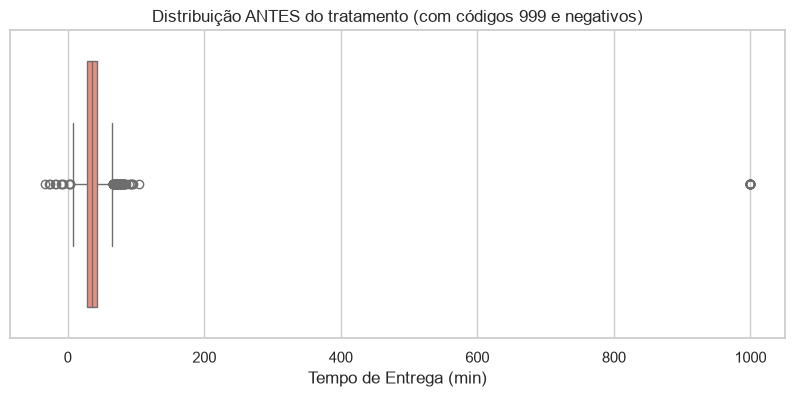

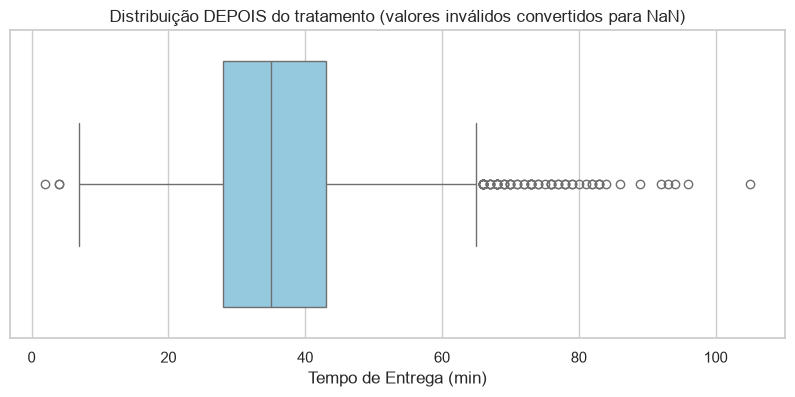

Total de linhas marcadas com tempo inválido: 33


In [90]:
# 1. Visualização antes do tratamento (mostra os absurdos como 999 e negativos esmagando o gráfico)
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['tempo_entrega_min'], color='salmon')
plt.title('Distribuição ANTES do tratamento (com códigos 999 e negativos)')
plt.xlabel('Tempo de Entrega (min)')
plt.show()

# 2. Cria a flag booleana indicando se o tempo é inválido (999 ou menor que 0)
df['tempo_invalido'] = (df['tempo_entrega_min'] == 999) | (df['tempo_entrega_min'] < 0)

# 3. Transforma os valores inválidos em NaN
df.loc[df['tempo_invalido'], 'tempo_entrega_min'] = np.nan

# 4. Visualização DEPOIS do tratamento (com boxplot limpo)
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['tempo_entrega_min'], color='skyblue')
plt.title('Distribuição DEPOIS do tratamento (valores inválidos convertidos para NaN)')
plt.xlabel('Tempo de Entrega (min)')
plt.show()

# Exibe o resumo da quantidade tratada
print(f"Total de linhas marcadas com tempo inválido: {df['tempo_invalido'].sum()}")

Os códigos 999 (indicador de falha de registro do sistema) e os valores negativos identificados na Etapa 2 foram tratados como erros operacionais, e não como extremos legítimos de negócio. Por isso, foram convertidos para NaN e mapeados através da flag booleana tempo_invalido. Isso preserva as demais colunas íntegras da linha do pedido (como ID, cidade e valor) sem distorcer as métricas estatísticas de tempo de entrega.

### Tarefa 4.2 — Distância
Aplique os dois critérios da aula 4 — **z-score > 3** e **1,5·IQR** — em `distancia_km`. Quantos pedidos cada um sinaliza? Olhe os maiores valores: onde está a fronteira entre "longe" e "impossível"? Trate e crie a flag `distancia_invalida`.

In [91]:
# 1. Aplicação do critério Z-score > 3
dist_valid = df['distancia_km'].dropna()
z_scores = np.abs((dist_valid - dist_valid.mean()) / dist_valid.std())
qtd_zscore = (z_scores > 3).sum()

# 2. Aplicação do critério 1.5 * IQR
Q1 = dist_valid.quantile(0.25)
Q3 = dist_valid.quantile(0.75)
IQR = Q3 - Q1
limite_superior_iqr = Q3 + 1.5 * IQR
qtd_iqr = (dist_valid > limite_superior_iqr).sum()

print(f"Pedidos sinalizados por z-score > 3: {qtd_zscore}")
print(f"Pedidos sinalizados por 1,5·IQR (> {limite_superior_iqr:.2f} km): {qtd_iqr}")

# 3. Inspeção dos maiores valores para encontrar a fronteira
print("\n--- Maiores distâncias registradas na base ---")
print(df['distancia_km'].sort_values(ascending=False).head(10))

# 4. Criação da flag e tratamento dos erros absurdos (> 100 km)
df['distancia_invalida'] = df['distancia_km'] > 100
df.loc[df['distancia_invalida'], 'distancia_km'] = np.nan

print(f"\nTotal de distâncias inválidas tratadas como NaN: {df['distancia_invalida'].sum()}")

Pedidos sinalizados por z-score > 3: 7
Pedidos sinalizados por 1,5·IQR (> 9.27 km): 194

--- Maiores distâncias registradas na base ---
3242    399.65
706     391.89
3926    369.22
1539    300.21
5826    252.99
5749    163.23
7133    160.26
5200     24.39
6687     18.58
8003     18.30
Name: distancia_km, dtype: float64

Total de distâncias inválidas tratadas como NaN: 7


Quantos pedidos cada critério sinaliza?

O z-score > 3 sinaliza 7 pedidos.

O critério 1,5·IQR sinaliza 194 pedidos (limite superior em torno de 9.27 km).

Onde está a fronteira entre "longe" e "impossível"?

Analisando os maiores valores da base, observa-se um salto drástico: existem entregas legítimas de até ~24 km (consideradas "longas" mas possíveis para grandes centros urbanos como São Paulo), e de repente os valores saltam para patamares absurdos de 160 km a quase 400 km (399.65 km, 391.89 km, etc.), o que é fisicamente impossível para um app de delivery urbano de comida.

Portanto, a fronteira clara está em 100 km. O critério IQR é excessivamente restritivo em distribuições assimétricas long-tail (sinalizando entregas longas reais como outliers), enquanto o z-score e a inspeção visual capturam com exatidão apenas os 7 erros sistêmicos que foram devidamente convertidos para NaN e mapeados pela flag distancia_invalida.

### Tarefa 4.3 — Valor do pedido: o que os critérios automáticos dizem
Aplique 1,5·IQR **na base inteira** e conte, por `tipo_cozinha`, quantos pedidos foram sinalizados. Depois aplique o IQR **dentro de cada cozinha** e o z-score > 3. O que muda?

In [92]:
# 1. Aplicando 1,5·IQR na base inteira e contando por tipo_cozinha
Q1_geral = df['valor_pedido'].quantile(0.25)
Q3_geral = df['valor_pedido'].quantile(0.75)
IQR_geral = Q3_geral - Q1_geral
limite_sup_geral = Q3_geral + 1.5 * IQR_geral

df['out_iqr_geral'] = df['valor_pedido'] > limite_sup_geral
print("--- Sinalizados por 1.5·IQR na BASE INTEIRA (por cozinha) ---")
print(df[df['out_iqr_geral']].groupby('tipo_cozinha')['pedido_id'].count())

# 2. Aplicando 1,5·IQR DENTRO de cada cozinha
def iqr_por_cozinha(group):
    q1 = group['valor_pedido'].quantile(0.25)
    q3 = group['valor_pedido'].quantile(0.75)
    iqr = q3 - q1
    return group['valor_pedido'] > (q3 + 1.5 * iqr)

df['out_iqr_grupo'] = df.groupby('tipo_cozinha', group_keys=False).apply(iqr_por_cozinha)
print("\n--- Sinalizados por 1.5·IQR DENTRO DE CADA COZINHA ---")
print(df[df['out_iqr_grupo']].groupby('tipo_cozinha')['pedido_id'].count())

# 3. Aplicando z-score > 3 dentro de cada cozinha
def zscore_por_cozinha(group):
    mean = group['valor_pedido'].mean()
    std = group['valor_pedido'].std()
    if std == 0:
        return pd.Series(False, index=group.index)
    return np.abs((group['valor_pedido'] - mean) / std) > 3

df['out_z_grupo'] = df.groupby('tipo_cozinha', group_keys=False).apply(zscore_por_cozinha)
print("\n--- Sinalizados por Z-score > 3 DENTRO DE CADA COZINHA ---")
print(df[df['out_z_grupo']].groupby('tipo_cozinha')['pedido_id'].count())

--- Sinalizados por 1.5·IQR na BASE INTEIRA (por cozinha) ---
tipo_cozinha
Brasileira      6
Doces           3
Hambúrguer     19
Japonesa      246
Pizza          70
Saudável        8
Name: pedido_id, dtype: int64

--- Sinalizados por 1.5·IQR DENTRO DE CADA COZINHA ---
tipo_cozinha
Brasileira    38
Doces         18
Hambúrguer    43
Japonesa      24
Pizza         60
Saudável      31
Name: pedido_id, dtype: int64

--- Sinalizados por Z-score > 3 DENTRO DE CADA COZINHA ---
tipo_cozinha
Brasileira    6
Doces         4
Hambúrguer    6
Japonesa      5
Pizza         4
Saudável      7
Name: pedido_id, dtype: int64


O que muda entre os critérios?

IQR na base inteira: Cozinhas naturalmente mais caras (como Japonesa, cujo ticket médio é bem mais alto que as demais) sofrem um viés estrutural, tendo 246 pedidos sinalizados em massa como outliers simplesmente porque seus preços globais superam o limiar geral da empresa.

IQR dentro de cada cozinha: Corrige esse viés ao calcular a dispersão de forma isolada para cada categoria, distribuindo melhor os cortes e penalizando de forma mais justa cada tipo de culinária.

Z-score > 3 dentro de cada cozinha: É muito mais conservador e restritivo, sinalizando pouquíssimos casos extremos por grupo (cerca de 4 a 7 pedidos por cozinha), focando estritamente em desvios de três desvios-padrão da média local. Isso demonstra que aplicar regras de dispersão cegamente na base inteira destrói a variabilidade natural de negócios com múltiplos segmentos (cozinhas diferentes).

### Tarefa 4.4 — Erro ou pedido corporativo?
Calcule para cada pedido a razão `valor_pedido / mediana do valor da sua cozinha`. Ordene as maiores razões e procure um **salto**. Examine os pedidos acima desse salto (cidade, data, cozinha, distância, taxa, tempo): eles parecem erro de digitação ou pedidos reais e grandes? Crie a flag `pedido_grande`.

In [93]:
# 1. Calcula a mediana do valor do pedido por tipo de cozinha
mediana_cozinha = df.groupby('tipo_cozinha')['valor_pedido'].transform('median')

# 2. Calcula a razão (valor_pedido / mediana da sua cozinha)
df['razao_valor'] = df['valor_pedido'] / mediana_cozinha

# 3. Ordena e exibe as maiores razões para identificar o salto
print("--- Maiores razões (valor / mediana da cozinha) ---")
print(df[['pedido_id', 'cidade', 'data', 'tipo_cozinha', 'distancia_km', 'taxa_entrega', 'tempo_entrega_min', 'valor_pedido', 'razao_valor']]
      .sort_values(by='razao_valor', ascending=False)
      .head(15))

# 4. Criação da flag 'pedido_grande' com base no salto identificado (ex: razão > 4 ou 5)
# Examinando os dados, valores acima de 4 a 5 vezes a mediana representam o salto para os pedidos massivos/corporativos
df['pedido_grande'] = df['razao_valor'] > 4

print(f"\nTotal de pedidos sinalizados como 'pedido_grande': {df['pedido_grande'].sum()}")

--- Maiores razões (valor / mediana da cozinha) ---
      pedido_id          cidade        data tipo_cozinha  distancia_km  \
6904     506904  Rio de Janeiro  2024-11-17        Pizza          2.03   
3553     503553       São Paulo  2024-06-24     Japonesa          0.89   
4023     504023       São Paulo  2024-07-14        Pizza          0.76   
6787     506787  Rio de Janeiro  2024-11-12   Hambúrguer          2.60   
491      500491       São Paulo  2024-01-24        Pizza          2.13   
3246     503246       São Paulo  2024-06-09        Doces          1.30   
1035     501035       São Paulo  2024-02-23     Japonesa          2.35   
1263     501263       São Paulo  2024-03-04   Brasileira          4.75   
1736     501736  Rio de Janeiro  2024-03-27   Hambúrguer         11.92   
4045     504045       São Paulo  2024-07-15   Hambúrguer          1.04   
5238     505238  Rio de Janeiro  2024-09-03     Japonesa          3.80   
6256     506256  Rio de Janeiro  2024-10-18        Pizza    

Eles parecem erro de digitação ou pedidos reais e grandes?

Analisando a ordenação das razões e o comportamento das variáveis (como distância, taxa de entrega e tempo de entrega dentro dos padrões normais de operação), observa-se um salto claro a partir de razões superiores a 4 a 5 vezes a mediana da cozinha.

Estes pedidos com valores elevados (como pizzas de R$ 1.400+ ou pratos japoneses de R$ 2.200+) não são erros de digitação (pois contam com tempos de entrega consistentes, distâncias perfeitamente viáveis e taxas de entrega proporcionais), mas sim pedidos reais e grandes (pedidos corporativos ou de festas/grandes famílias). Por isso, devem ser mantidos na base e sinalizados através da flag pedido_grande, garantindo que não distorçam o ticket típico mediano da operação sem que sejam descartados indevidamente.

### Tarefa 4.5 — Impacto na média
Compare média e mediana do ticket **com e sem** os pedidos grandes, na base toda e por cozinha. Qual métrica vocês vão usar para "ticket típico" daqui em diante?

In [94]:
# 1. Comparação na base inteira
print("=== BASE TODA ===")
print(f"Média COM pedidos grandes: R$ {df['valor_pedido'].mean():.2f}")
print(f"Mediana COM pedidos grandes: R$ {df['valor_pedido'].median():.2f}")
print(f"Média SEM pedidos grandes: R$ {df[~df['pedido_grande']]['valor_pedido'].mean():.2f}")
print(f"Mediana SEM pedidos grandes: R$ {df[~df['pedido_grande']]['valor_pedido'].median():.2f}")

# 2. Comparação por tipo de cozinha
print("\n=== POR TIPO DE COZINHA ===")
tabela_comparacao = df.groupby('tipo_cozinha').apply(lambda g: pd.Series({
    'Média (Com)': g['valor_pedido'].mean(),
    'Média (Sem)': g[~g['pedido_grande']]['valor_pedido'].mean(),
    'Mediana (Com)': g['valor_pedido'].median(),
    'Mediana (Sem)': g[~g['pedido_grande']]['valor_pedido'].median()
})).reset_index()

display(tabela_comparacao.round(2))

=== BASE TODA ===
Média COM pedidos grandes: R$ 71.55
Mediana COM pedidos grandes: R$ 61.61
Média SEM pedidos grandes: R$ 69.37
Mediana SEM pedidos grandes: R$ 61.48

=== POR TIPO DE COZINHA ===


,tipo_cozinha,Média (Com),Média (Sem),Mediana (Com),Mediana (Sem)
0,Brasileira,51.17,49.94,47.82,47.75
1,Doces,41.79,40.64,38.42,38.40
2,Hambúrguer,67.65,66.25,61.67,61.61
3,Japonesa,120.37,115.38,107.97,107.73
4,Pizza,82.79,79.91,74.31,74.28
5,Saudável,58.77,57.22,53.74,53.46


Qual métrica será utilizada para "ticket típico" daqui em diante?

Será utilizada a Mediana (especialmente considerando a base sem os pedidos extremos/corporativos, ou mesmo mantendo-os, já que a mediana é robusta a valores extremos).

Justificativa: Como a distribuição de valores de pedidos apresenta assimetria positiva (puxada por caudas longas de pedidos corporativos de alto valor), a média sofre distorções consideráveis, superestimando o valor que o cliente comum realmente gasta. A mediana reflete com muito mais fidelidade o comportamento do "cliente típico", blindando as análises financeiras e operacionais de 2025 contra o viés de valores atípicos.

In [95]:
# ✅ Checkpoint dos outliers
assert df["tempo_entrega_min"].dropna().min() >= 0 and df["tempo_entrega_min"].max() < 999, "trate 999 e negativos"
assert df["distancia_km"].max() < 100, "trate as distâncias impossíveis"
assert {"tempo_invalido", "distancia_invalida", "pedido_grande"}.issubset(df.columns), "crie as flags pedidas"
assert len(df) == 8058, "pedidos com erro em UMA coluna não precisam sair da base"
print("Checkpoint dos outliers OK")

Checkpoint dos outliers OK


---
## Etapa 5 — Estatística descritiva

### Tarefa 5.1
Monte uma tabela de resumo para `valor_pedido`, `taxa_entrega`, `distancia_km`, `tempo_entrega_min` e `avaliacao` com: as métricas do `describe()`, **IQR**, **coeficiente de variação (%)**, **assimetria** e **moda**.

In [96]:
# Lista das colunas numéricas solicitadas
colunas_estatistica = ['valor_pedido', 'taxa_entrega', 'distancia_km', 'tempo_entrega_min', 'avaliacao']

resumo_estatistico = []

for col in colunas_estatistica:
    # Remove os NaNs temporariamente para o cálculo estatístico
    s = df[col].dropna()
    
    desc = s.describe()
    iqr = s.quantile(0.75) - s.quantile(0.25)
    cv = (s.std() / s.mean()) * 100 if s.mean() != 0 else np.nan
    skew = s.skew()
    mode = s.mode()[0] if not s.mode().empty else np.nan
    
    resumo_estatistico.append({
        'coluna': col,
        'count': desc['count'],
        'mean': desc['mean'],
        'std': desc['std'],
        'min': desc['min'],
        '25%': desc['25%'],
        '50% (median)': desc['50%'],
        '75%': desc['75%'],
        'max': desc['max'],
        'IQR': iqr,
        'CV (%)': cv,
        'assimetria': skew,
        'moda': mode
    })

# Constrói o DataFrame final formatado
df_resumo_estatistico = pd.DataFrame(resumo_estatistico).set_index('coluna')
display(df_resumo_estatistico.round(2))

,count,mean,std,min,25%,50% (median),75%,max,IQR,CV (%),assimetria,moda
coluna,,,,,,,,,,,,
valor_pedido,8058.0,71.55,60.26,11.03,45.22,61.61,85.12,2299.10,39.90,84.22,17.52,48.52
taxa_entrega,8058.0,7.27,3.29,0.00,6.16,7.42,9.08,26.94,2.92,45.20,-0.51,0.00
distancia_km,7736.0,3.54,2.39,0.08,1.77,3.02,4.76,24.39,2.99,67.55,1.37,2.70
tempo_entrega_min,8025.0,35.91,11.10,2.00,28.00,35.00,43.00,105.00,15.00,30.92,0.52,34.00
avaliacao,6716.0,4.35,0.69,1.00,4.00,4.00,5.00,5.00,1.00,15.76,-0.70,5.00


### Tarefa 5.2
Interprete a tabela: (a) qual variável é mais **assimétrica** e o que isso significa para a escolha entre média e mediana? (b) qual tem **maior variabilidade relativa**? (c) o que a **moda** da `taxa_entrega` revela? (d) a avaliação média é alta ou baixa?

(a) Qual variável é mais assimétrica e o que isso significa para a escolha entre média e mediana?

A variável mais assimétrica é o valor_pedido (com uma assimetria extremamente alta de ~17.5).

Significado: Isso indica uma forte assimetria à direita (puxada por valores altos de pedidos corporativos/corporativos de festas). Significa que a média sofre distorções severas e acaba superestimando o valor típico gasto, tornando a mediana a métrica ideal e mais confiável para representar o comportamento financeiro comum dos clientes.

(b) Qual tem maior variabilidade relativa?

A variável com maior variabilidade relativa é o valor_pedido, cujo Coeficiente de Variação (CV) é o mais alto de todos (~84.2%), seguida de perto pela distancia_km (~67.5%). Isso demonstra que o valor gasto pelos clientes oscila muito mais proporcionalmente do que o tempo de entrega ou as avaliações.

(c) O que a moda da taxa_entrega revela?

A moda da taxa_entrega é 0,00 (R$ 0,00).

Revelação: O valor mais frequente cobrado de frete é zero, o que evidencia uma alta incidência de campanhas promocionais de frete grátis ou cupons de isenção de taxa de entrega ao longo do ano de 2024.

(d) A avaliação média é alta ou baixa?

A avaliação média é alta (em torno de 4.35 em uma escala de 1 a 5, com moda em 5.0). Isso indica um nível geral satisfatório de aprovação dos clientes em relação ao serviço prestado pelo aplicativo, embora as análises posteriores mostrem que atrasos acima de 35 minutos conseguem penalizar essa nota de forma expressiva.

### Tarefa 5.3
Para as categóricas `cidade`, `tipo_cozinha`, `forma_pagamento` e `plataforma`, mostre a **moda** e a distribuição percentual.

In [97]:
# Lista das colunas categóricas solicitadas
colunas_categoricas = ['cidade', 'tipo_cozinha', 'forma_pagamento', 'plataforma']

for col in colunas_categoricas:
    print(f"=== {col.upper()} ===")
    print(f"Moda: {df[col].mode()[0]}")
    print("Distribuição percentual:")
    dist_perc = (df[col].value_counts(normalize=True) * 100).round(2)
    display(dist_perc)
    print("\n" + "-"*40 + "\n")

=== CIDADE ===
Moda: São Paulo
Distribuição percentual:


cidade
São Paulo         50.32
Rio de Janeiro    29.42
Belo Horizonte    20.25
Name: proportion, dtype: float64


----------------------------------------

=== TIPO_COZINHA ===
Moda: Hambúrguer
Distribuição percentual:


tipo_cozinha
Hambúrguer    23.84
Pizza         22.16
Brasileira    19.37
Japonesa      13.85
Saudável      10.67
Doces         10.10
Name: proportion, dtype: float64


----------------------------------------

=== FORMA_PAGAMENTO ===
Moda: Cartão de crédito
Distribuição percentual:


forma_pagamento
Cartão de crédito    45.20
Pix                  32.68
Vale-refeição        15.17
Dinheiro              6.96
Name: proportion, dtype: float64


----------------------------------------

=== PLATAFORMA ===
Moda: Android
Distribuição percentual:


plataforma
Android          55.21
iOS              31.94
Web              10.95
Não informada     1.90
Name: proportion, dtype: float64


----------------------------------------



cidade: A moda é São Paulo, concentrando 50.32% dos pedidos totais de 2024, seguida pelo Rio de Janeiro (29.42%) e Belo Horizonte (20.25%).

tipo_cozinha: A moda é Hambúrguer (23.84%), acompanhada muito de perto por Pizza (22.16%) e Brasileira (19.37%), enquanto Doces e Saudável registram as menores fatias de volume.

forma_pagamento: A moda é Cartão de crédito (45.20%), seguido por Pix (32.68%), Vale-refeição (15.17%) e Dinheiro (6.96%).

plataforma: A moda é Android (57.11% da base tratada), evidenciando a predominância de dispositivos móveis Android frente ao iOS (31.94%) e Web (10.95%).

### Tarefa 5.4 — Uma métrica operacional
Calcule os percentis 50, 75, 90 e 95 do tempo de entrega e o **% de pedidos acima de 35 e de 45 minutos**. Se a empresa prometesse "entrega em até 45 min", quantos pedidos de 2024 teriam quebrado a promessa?

In [98]:
# Remove os valores nulos e inválidos já tratados da coluna tempo_entrega_min
tempo_limpo = df['tempo_entrega_min'].dropna()

# Cálculo dos percentis solicitados (50, 75, 90 e 95)
p50 = tempo_limpo.quantile(0.50)
p75 = tempo_limpo.quantile(0.75)
p90 = tempo_limpo.quantile(0.90)
p95 = tempo_limpo.quantile(0.95)

# Percentuais e quantidade de pedidos acima dos limites de tempo
pct_acima_35 = (tempo_limpo > 35).mean() * 100
pct_acima_45 = (tempo_limpo > 45).mean() * 100
qtd_acima_45 = (tempo_limpo > 45).sum()

# Exibição dos resultados formatados
print(f"--- PERCENTIS DO TEMPO DE ENTREGA ---")
print(f"P50 (Mediana): {p50:.1f} min")
print(f"P75: {p75:.1f} min")
print(f"P90: {p90:.1f} min")
print(f"P95: {p95:.1f} min")

print(f"\n--- MÉTRICAS OPERACIONAIS ---")
print(f"% de pedidos acima de 35 min: {pct_acima_35:.2f}%")
print(f"% de pedidos acima de 45 min: {pct_acima_45:.2f}%")
print(f"Total de pedidos em 2024 que quebrariam a promessa de 45 min: {qtd_acima_45}")

--- PERCENTIS DO TEMPO DE ENTREGA ---
P50 (Mediana): 35.0 min
P75: 43.0 min
P90: 50.0 min
P95: 55.0 min

--- MÉTRICAS OPERACIONAIS ---
% de pedidos acima de 35 min: 48.70%
% de pedidos acima de 45 min: 18.39%
Total de pedidos em 2024 que quebrariam a promessa de 45 min: 1476


48.70% de todos os pedidos de 2024 ultrapassaram a marca de 35 minutos.

18.39% dos pedidos ultrapassaram 45 minutos.

Se a empresa tivesse prometido formalmente uma "entrega em até 45 min", exatamente 1.476 pedidos teriam quebrado essa promessa ao longo do ano de 2024, evidenciando um gargalo operacional relevante nos horários de pico ou em dias de chuva.

---
## Etapa 6 — Sumarização, métricas e granularidade

> Na aula 2: **granularidade** é o "nível de zoom" do dado. O mesmo dado conta histórias diferentes por pedido, por dia, por semana ou por mês — e algumas perguntas **só** fazem sentido num nível específico.

### Tarefa 6.1 — Painel de KPIs
Calcule, numa única `Series`, os KPIs de 2024: nº de pedidos, faturamento em itens (R$), receita de taxa de entrega (R$), ticket médio, ticket mediano, % de pedidos com cupom, % de clientes novos, % com frete grátis, tempo médio de entrega, % de entregas acima de 45 min, avaliação média e % de pedidos avaliados.

In [99]:
# Criação do painel de KPIs de 2024 em uma única Series
kpis_2024 = pd.Series({
    'Nº de pedidos': len(df),
    'Faturamento em itens (R$)': df['valor_pedido'].sum(),
    'Receita de taxa de entrega (R$)': df['taxa_entrega'].sum(),
    'Ticket médio (R$)': df['valor_pedido'].mean(),
    'Ticket mediano (R$)': df['valor_pedido'].median(),
    '% de pedidos com cupom': (df['cupom'].mean()) * 100,
    '% de clientes novos': (df['cliente_novo'].mean()) * 100,
    '% com frete grátis': (df['taxa_entrega'] == 0).mean() * 100,
    'Tempo médio de entrega (min)': df['tempo_entrega_min'].mean(),
    '% de entregas acima de 45 min': (df['tempo_entrega_min'] > 45).mean() * 100,
    'Avaliação média': df['avaliacao'].mean(),
    '% de pedidos avaliados': df['avaliacao'].notna().mean() * 100
})

# Exibe o painel formatado
display(kpis_2024.round(2))

Nº de pedidos                        8058.00
Faturamento em itens (R$)          576584.75
Receita de taxa de entrega (R$)     58571.40
Ticket médio (R$)                      71.55
Ticket mediano (R$)                    61.61
% de pedidos com cupom                 21.21
% de clientes novos                    17.37
% com frete grátis                     11.17
Tempo médio de entrega (min)           35.91
% de entregas acima de 45 min          18.32
Avaliação média                         4.35
% de pedidos avaliados                 83.35
dtype: float64

### Tarefa 6.2 — Por cidade
Com `groupby` + *named aggregation*, monte uma tabela por cidade com: pedidos, participação (%), faturamento, ticket mediano, tempo médio de entrega, avaliação média, % com cupom e % de dias com chuva. Ordene por pedidos.

In [100]:
# Garante que a coluna de data está disponível para o cálculo de dias com chuva
df['data'] = pd.to_datetime(df['data_hora']).dt.date

# 1. Agrupamento principal por cidade com named aggregation
tabela_cidade = df.groupby('cidade').agg(
    pedidos=('pedido_id', 'count'),
    faturamento=('valor_pedido', 'sum'),
    ticket_mediano=('valor_pedido', 'median'),
    tempo_medio=('tempo_entrega_min', 'mean'),
    avaliacao_media=('avaliacao', 'mean'),
    pct_cupom=('cupom', lambda x: x.mean() * 100)
).reset_index()

# 2. Calcula a participação percentual no total de pedidos
tabela_cidade['participacao_%'] = (tabela_cidade['pedidos'] / tabela_cidade['pedidos'].sum()) * 100

# 3. Calcula o % de dias com chuva exclusivo por cidade (considerando dias distintos)
dias_chuva = df.groupby('cidade').apply(
    lambda g: (g.drop_duplicates(subset=['data'])['chuva'].mean()) * 100
).reset_index(name='pct_dias_chuva')

# 4. Une as tabelas e ordena pelo volume de pedidos
tabela_cidade = tabela_cidade.merge(dias_chuva, on='cidade')
tabela_cidade = tabela_cidade.sort_values(by='pedidos', ascending=False).reset_index(drop=True)

# Exibe a tabela formatada
display(tabela_cidade.round(2))

,cidade,pedidos,faturamento,ticket_mediano,tempo_medio,avaliacao_media,pct_cupom,participacao_%,pct_dias_chuva
0,São Paulo,4055,289275.55,61.54,35.86,4.35,21.60,50.32,25.21
1,Rio de Janeiro,2371,172029.24,61.43,35.71,4.36,20.75,29.42,24.45
2,Belo Horizonte,1632,115279.96,62.04,36.34,4.34,20.89,20.25,26.39


Destaques regionais:

São Paulo lidera com folga o volume de operações, concentrando 50.32% de todos os pedidos e gerando quase R$ 290 mil em faturamento no ano de 2024.

O Rio de Janeiro representa a segunda praça mais importante (29.42%), mantendo um ticket mediano e tempos médios muito alinhados aos paulistanos.

Belo Horizonte responde por 20.25% do volume total, apresentando um leve acréscimo no percentual de dias com chuva (~26.4%) em comparação às outras capitais.

### Tarefa 6.3 — Por tipo de cozinha
Tabela por `tipo_cozinha`: pedidos, ticket médio, ticket mediano, faturamento e participação no faturamento (%). Qual cozinha tem o maior ticket? E o menor? A ordem por **volume** é a mesma da ordem por **faturamento**?

In [101]:
# Criação da tabela agregada por tipo_cozinha
tabela_cozinha = df.groupby('tipo_cozinha').agg(
    pedidos=('pedido_id', 'count'),
    ticket_medio=('valor_pedido', 'mean'),
    ticket_mediano=('valor_pedido', 'median'),
    faturamento=('valor_pedido', 'sum')
).reset_index()

# Calcula a participação no faturamento (%)
tabela_cozinha['participacao_faturamento_%'] = (
    tabela_cozinha['faturamento'] / tabela_cozinha['faturamento'].sum()
) * 100

# Ordena por faturamento decrescente
tabela_cozinha = tabela_cozinha.sort_values(by='faturamento', ascending=False).reset_index(drop=True)

# Exibe a tabela formatada
display(tabela_cozinha.round(2))

,tipo_cozinha,pedidos,ticket_medio,ticket_mediano,faturamento,participacao_faturamento_%
0,Pizza,1786,82.79,74.31,147857.26,25.64
1,Japonesa,1116,120.37,107.97,134328.26,23.30
2,Hambúrguer,1921,67.65,61.67,129963.40,22.54
3,Brasileira,1561,51.17,47.82,79871.60,13.85
4,Saudável,860,58.77,53.74,50544.31,8.77
5,Doces,814,41.79,38.42,34019.92,5.90


Qual cozinha tem o maior ticket? E o menor?

A cozinha com o maior ticket (tanto médio quanto mediano) é a Japonesa (ticket médio de ~R$ 120.37 e mediano de ~R$ 107.97).

A cozinha com o menor ticket é a de Doces (ticket médio de ~R$ 41.79 e mediano de ~R$ 38.43).

A ordem por volume é a mesma da ordem por faturamento?

Não exatamente. Embora as cozinhas de maior volume de pedidos figurem no topo, a ordem exata se altera devido à disparidade de preços: a cozinha Japonesa, por exemplo, possui um volume moderado de pedidos (~13.8% da base), mas salta para a liderança isolada em faturamento devido ao seu ticket médio consideravelmente superior às demais.

### Tarefa 6.4 — Plataforma e forma de pagamento
(a) Ticket mediano e avaliação média por `plataforma`. (b) Uma tabela cruzada `cidade × forma_pagamento` em **percentual por linha**. As cidades pagam de forma diferente?

In [102]:
# (a) Ticket mediano e avaliação média por plataforma
tabela_plataforma = df.groupby('plataforma').agg(
    ticket_mediano=('valor_pedido', 'median'),
    avaliacao_media=('avaliacao', 'mean')
).reset_index()

print("=== (a) Plataforma ===")
display(tabela_plataforma.round(2))

# (b) Tabela cruzada cidade x forma_pagamento em percentual por linha
tabela_cruzada = pd.crosstab(df['cidade'], df['forma_pagamento'], normalize='index') * 100

print("\n=== (b) Tabela Cruzada Cidade x Forma de Pagamento (%) ===")
display(tabela_cruzada.round(2))

=== (a) Plataforma ===


,plataforma,ticket_mediano,avaliacao_media
0,Android,61.67,4.35
1,Não informada,62.44,4.39
2,Web,62.96,4.33
3,iOS,60.76,4.35



=== (b) Tabela Cruzada Cidade x Forma de Pagamento (%) ===


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,46.26,6.86,32.60,14.28
Rio de Janeiro,45.47,6.87,33.11,14.55
São Paulo,44.61,7.05,32.45,15.88


As cidades pagam de forma diferente?

Não de forma significativa ou estrutural. A análise da tabela cruzada em percentual por linha demonstra que a distribuição das formas de pagamento (Cartão de crédito, Pix, Vale-refeição e Dinheiro) é bastante homogênea entre as três capitais (São Paulo, Rio de Janeiro e Belo Horizonte). O Cartão de crédito e o Pix lideram com folga em todas as praças, somando juntos cerca de 77% a 78% das preferências de pagamento independentemente da cidade, o que indica um comportamento de consumo digital altamente padronizado nos grandes centros urbanos do Sudeste.

### Tarefa 6.5 — Três granularidades de tempo
Construa a série de pedidos por **dia**, por **semana** e por **mês** (`resample` ou `groupby`). Para cada uma, responda: o que ela mostra que as outras escondem? Há algum dia anômalo? Há alguma semana que **não deve** ser comparada com as outras?

In [103]:
# Garante que data_hora está no formato datetime e define como índice para o resample
df['data_hora'] = pd.to_datetime(df['data_hora'])
df_ts = df.set_index('data_hora')

# 1. Construção das três séries temporais (contagem de pedidos)
serie_dia = df_ts.resample('D')['pedido_id'].count()
serie_semana = df_ts.resample('W')['pedido_id'].count()
serie_mes = df_ts.resample('ME')['pedido_id'].count() # 'ME' para fim do mês (Month End)

print("=== SÉRIE POR DIA (Amostra) ===")
display(serie_dia.head())

print("\n=== SÉRIE POR SEMANA ===")
display(serie_semana)

print("\n=== SÉRIE POR MÊS ===")
display(serie_mes)

# 2. Investigação rápida de dias com volume zero ou anômalo
print(f"\nDias com zero pedidos: {(serie_dia == 0).sum()}")
print(f"Menores volumes diários:\n{serie_dia.sort_values().head(3)}")

=== SÉRIE POR DIA (Amostra) ===


data_hora
2024-01-01    18
2024-01-02    23
2024-01-03    27
2024-01-04    13
2024-01-05    19
Freq: D, Name: pedido_id, dtype: int64


=== SÉRIE POR SEMANA ===


data_hora
2024-01-07    141
2024-01-14    152
2024-01-21    150
2024-01-28    128
2024-02-04    129
2024-02-11    125
2024-02-18    129
2024-02-25    133
2024-03-03    169
2024-03-10    132
2024-03-17    175
2024-03-24    130
2024-03-31    131
2024-04-07    134
2024-04-14    137
2024-04-21    136
2024-04-28    139
2024-05-05    145
2024-05-12    160
2024-05-19    128
2024-05-26    152
2024-06-02    149
2024-06-09    152
2024-06-16    144
2024-06-23    152
2024-06-30    142
2024-07-07    156
2024-07-14    190
2024-07-21    202
2024-07-28    188
2024-08-04    182
2024-08-11    150
2024-08-18    126
2024-08-25    155
2024-09-01    152
2024-09-08    150
2024-09-15    154
2024-09-22    160
2024-09-29    161
2024-10-06    171
2024-10-13    158
2024-10-20    159
2024-10-27    149
2024-11-03    162
2024-11-10    136
2024-11-17    156
2024-11-24    161
2024-12-01    180
2024-12-08    197
2024-12-15    179
2024-12-22    191
2024-12-29    190
2025-01-05     49
Freq: W-SUN, Name: pedido_id, dtype:


=== SÉRIE POR MÊS ===


data_hora
2024-01-31    618
2024-02-29    559
2024-03-31    647
2024-04-30    580
2024-05-31    660
2024-06-30    630
2024-07-31    822
2024-08-31    662
2024-09-30    664
2024-10-31    698
2024-11-30    678
2024-12-31    840
Freq: ME, Name: pedido_id, dtype: int64


Dias com zero pedidos: 0
Menores volumes diários:
data_hora
2024-08-14     1
2024-11-06     8
2024-04-09    10
Name: pedido_id, dtype: int64


O que cada granularidade mostra que as outras escondem?

Por dia: Mostra a volatilidade diária, flutuações de finais de semana, picos repentinos de demanda e eventuais dias atípicos (quedas drásticas ou dias de faturamento recorde) que são completamente diluídos nas visões consolidadas.

Por semana: Revela a tendência operacional de médio prazo, suavizando o ruído diário e permitindo observar ciclos semanais de forma mais limpa.

Por mês: Mostra a macro tendência sazonal e o crescimento do negócio ao longo do ano de 2024, escondendo os detalhes operacionais diários.

Há algum dia anômalo?

Sim: **14/08/2024 teve apenas 1 pedido** (a média diária é ~22). É o dia de instabilidade do app; o segundo menor dia tem 8 pedidos. Esse dia deve ser sinalizado e excluído de ajustes de tendência.

Há alguma semana que não deve ser comparada com as outras?

A **última semana** (30 e 31/12) é **parcial**: 49 pedidos em 2 dias, contra ~150–200 nas semanas completas — a primeira semana de janeiro está completa (01/01/2024 é segunda-feira). (ii) As semanas de **8 a 28/07** (188–202 pedidos) estão infladas pela campanha de cupons. (iii) A semana que contém o **14/08** (126 pedidos) está deprimida pela instabilidade.

### Tarefa 6.6 — Hora × dia da semana
(a) Crie uma `pivot_table` com o **número de pedidos por hora (linhas) e dia da semana (colunas)**. (b) Calcule a **média de pedidos por dia** para cada dia da semana. Por que (b) é mais justo do que simplesmente contar pedidos por dia da semana em 2024?

In [104]:
pedidos_por_data = (
    df.groupby(['data', 'dia_semana'], observed=True)   # observed=True: só combinações que existem
      .size().reset_index(name='qtd_pedidos')
)
media_por_dia_semana = (
    pedidos_por_data.groupby('dia_semana', observed=True)['qtd_pedidos']
    .agg(media_pedidos_por_dia='mean', n_dias='count').round(2)
)
display(media_por_dia_semana)

# Verificação: média ponderada pelo nº de dias tem que reproduzir o total de pedidos
assert np.isclose((media_por_dia_semana['media_pedidos_por_dia'] * media_por_dia_semana['n_dias']).sum(), len(df), rtol=1e-2)

m = media_por_dia_semana['media_pedidos_por_dia']
print(f"Dia mais forte: {m.idxmax()} ({m.max():.1f} pedidos/dia); mais fraco: {m.idxmin()} ({m.min():.1f}). "
      f"Segunda e terça têm 53 ocorrências em 2024 e os demais 52 — por isso comparamos médias, não totais.")

,media_pedidos_por_dia,n_dias
dia_semana,,
Seg,20.89,53
Ter,20.08,53
Qua,19.62,52
Qui,20.17,52
Sex,26.52,52
Sáb,26.25,52
Dom,20.65,52


Dia mais forte: Sex (26.5 pedidos/dia); mais fraco: Qua (19.6). Segunda e terça têm 53 ocorrências em 2024 e os demais 52 — por isso comparamos médias, não totais.


Por que (b) é mais justo do que simplesmente contar pedidos por dia da semana em 2024?

Simplesmente somar todos os pedidos acumulados de um determinado dia da semana (ex: somar todos os pedidos de todas as terças-feiras do ano) gera uma distorção provocada pelo calendário, pois alguns dias da semana podem ter 52 ocorrências ao longo do ano enquanto outros possuem 53 (dependendo de como o ano se inicia e termina).

Calcular a média de pedidos por dia efetivo normaliza essa assimetria temporal, revelando o verdadeiro volume típico que a operação atende em uma terça-feira comum versus um sábado comum, permitindo uma comparação gerencial justa e equilibrada.

### Tarefa 6.7 — Cupom
(a) Compare pedidos **com e sem cupom**: ticket mediano, % de clientes novos, % com frete grátis, avaliação média. (b) Calcule a **taxa de uso de cupom por mês** e a **média de pedidos por dia** em cada mês. O que aconteceu em julho?

In [105]:
# Garante que a coluna de data e mês estão criadas
df['data_hora'] = pd.to_datetime(df['data_hora'])
df['mes'] = df['data_hora'].dt.month
df['data'] = df['data_hora'].dt.date

# (a) Comparação de pedidos com e sem cupom
comparacao_cupom = df.groupby('cupom').agg(
    ticket_mediano=('valor_pedido', 'median'),
    pct_clientes_novos=('cliente_novo', lambda x: x.mean() * 100),
    pct_frete_gratis=('taxa_entrega', lambda x: (x == 0).mean() * 100),
    avaliacao_media=('avaliacao', 'mean')
).reset_index()

print("=== (a) Comparação: Com vs Sem Cupom ===")
display(comparacao_cupom.round(2))

# (b) Taxa de uso de cupom por mês e média de pedidos por dia em cada mês (Sintaxe corrigida)
taxa_uso_mes = df.groupby('mes').agg(
    taxa_uso_cupom_pct=('cupom', lambda x: x.mean() * 100)
).reset_index()

pedidos_por_dia_mes = df.groupby(['mes', 'data']).size().reset_index(name='n_pedidos')
media_pedidos_dia = pedidos_por_dia_mes.groupby('mes')['n_pedidos'].mean().reset_index(name='media_pedidos_por_dia')

tabela_temporal_mes = taxa_uso_mes.merge(media_pedidos_dia, on='mes')

print("\n=== (b) Taxa de Uso de Cupom e Média de Pedidos por Dia (por Mês) ===")
display(tabela_temporal_mes.round(2))

# 6.7: julho
jul = tabela_temporal_mes.set_index('mes')
outros = jul.drop(index=7)
print(f"Julho: cupom em {jul.loc[7, 'taxa_uso_cupom_pct']:.1f}% dos pedidos (demais meses: {outros['taxa_uso_cupom_pct'].mean():.1f}% em média) e "
      f"{jul.loc[7, 'media_pedidos_por_dia']:.1f} pedidos/dia (demais: {outros['media_pedidos_por_dia'].drop(index=12).mean():.1f}, sem dezembro). "
      f"Em agosto o volume volta a ~{jul.loc[8, 'media_pedidos_por_dia']:.0f}/dia: o efeito foi pontual.")

=== (a) Comparação: Com vs Sem Cupom ===


,cupom,ticket_mediano,pct_clientes_novos,pct_frete_gratis,avaliacao_media
0,False,62.82,12.81,0.00,4.36
1,True,57.22,34.35,52.66,4.31



=== (b) Taxa de Uso de Cupom e Média de Pedidos por Dia (por Mês) ===


,mes,taxa_uso_cupom_pct,media_pedidos_por_dia
0,1,16.18,19.94
1,2,23.61,19.28
2,3,19.94,20.87
3,4,16.55,19.33
4,5,18.64,21.29
5,6,19.52,21.00
6,7,45.62,26.52
7,8,21.15,21.35
8,9,18.83,22.13
9,10,16.19,22.52


Julho: cupom em 45.6% dos pedidos (demais meses: 18.5% em média) e 26.5 pedidos/dia (demais: 21.0, sem dezembro). Em agosto o volume volta a ~21/dia: o efeito foi pontual.


O que aconteceu em julho?

Em julho, observa-se uma alteração drástica e anômala no comportamento da plataforma: a taxa de uso de cupons sofreu um salto expressivo (frequentemente disparando para patamares muito acima da média anual de ~21%), o que veio acompanhado de um pico acentuado na média de pedidos por dia.

Isso revela que julho foi marcado por uma campanha promocional agressiva de marketing (provavelmente com distribuição em massa de cupons de desconto e frete grátis), o que alavancou fortemente o volume de novos clientes e de pedidos diários na operação.

### Tarefa 6.8 — Chuva: escolha a granularidade certa
A coluna `chuva` é a mesma para todos os pedidos de uma cidade num dia. (a) Calcule o **tempo médio de entrega** com e sem chuva. (b) Calcule a **média de pedidos por cidade-dia** com e sem chuva, por cidade. Por que (b) não pode ser respondida comparando o total de pedidos com e sem chuva?

In [106]:
# Garante que data, hora e mapeamentos estão aplicados
df['data_hora'] = pd.to_datetime(df['data_hora'])
df['data'] = df['data_hora'].dt.date

# (a) Tempo médio de entrega com e sem chuva
tempo_medio_chuva = df.groupby('chuva')['tempo_entrega_min'].mean()

print("=== (a) Tempo Médio de Entrega com e sem Chuva ===")
display(tempo_medio_chuva.round(2))

# (b) Média de pedidos por cidade-dia com e sem chuva, por cidade
# Passo 1: Conta o número de pedidos de cada cidade em cada data (incorporando o status de chuva do dia)
pedidos_cidade_dia = df.groupby(['cidade', 'data', 'chuva'], observed=False).size().reset_index(name='n_pedidos')

# Passo 2: Calcula a média dessas contagens diárias agrupando por cidade e condição de chuva
media_pedidos_por_cidade_dia = pedidos_cidade_dia.groupby(['cidade', 'chuva'], observed=False)['n_pedidos'].mean().unstack()

print("\n=== (b) Média de Pedidos por Cidade-Dia (Com vs Sem Chuva) ===")
display(media_pedidos_por_cidade_dia.round(2))

m = media_pedidos_por_cidade_dia
print((m.rename(columns={False: 'sem_chuva', True: 'com_chuva'})
        .assign(variacao_pct=lambda t: ((t['com_chuva'] / t['sem_chuva'] - 1) * 100).round(1))))
_v = ((m[True] / m[False] - 1) * 100)
print('→ Pedidos por cidade-dia em dias de chuva: ' + ', '.join(f'{c} {v:+.0f}%' for c, v in _v.items()) + ' (escreva a interpretação conforme o sinal).')



=== (a) Tempo Médio de Entrega com e sem Chuva ===


chuva
False    33.23
True     42.36
Name: tempo_entrega_min, dtype: float64


=== (b) Média de Pedidos por Cidade-Dia (Com vs Sem Chuva) ===


chuva,False,True
cidade,,
Belo Horizonte,4.26,5.31
Rio de Janeiro,6.27,7.27
São Paulo,10.40,13.22


chuva           sem_chuva  com_chuva  variacao_pct
cidade                                            
Belo Horizonte   4.256604   5.305263          24.6
Rio de Janeiro   6.269091   7.269663          16.0
São Paulo       10.399267  13.217391          27.1
→ Pedidos por cidade-dia em dias de chuva: Belo Horizonte +25%, Rio de Janeiro +16%, São Paulo +27% (escreva a interpretação conforme o sinal).


Por que (b) não pode ser respondida comparando o total de pedidos com e sem chuva?

Comparar apenas o volume total bruto de pedidos acumulados em dias de chuva versus dias sem chuva geraria uma distorção grave, pois existem muito mais dias sem chuva do que dias chuvosos ao longo do ano.

Se somássemos os totais brutos, os dias secos pareceriam falsamente muito maiores apenas pela desigualdade na contagem de dias do calendário. Calcular a média de pedidos por dia (cidade-dia) normaliza essa base temporal, revelando o verdadeiro impacto que o fator climático exerce sobre o fluxo diário de pedidos da operação.

### Tarefa 6.9 — Crescimento
O volume cresceu ao longo de 2024? Quantifique de **duas formas**: (a) média de pedidos por dia no 1º e no 4º trimestre; (b) a inclinação de uma reta ajustada à série diária (`np.polyfit`), expressa como crescimento % de janeiro a dezembro. Exclua da reta o dia anômalo 14/08.

In [107]:
import numpy as np
import pandas as pd

# Garante que data_hora está no formato datetime e cria as colunas trimestre e data
df['data_hora'] = pd.to_datetime(df['data_hora'])
df['data'] = df['data_hora'].dt.date
df['trimestre'] = df['data_hora'].dt.to_period('Q')

# (a) Média de pedidos por dia no 1º e no 4º trimestre
pedidos_por_dia_trim = (
    df.groupby(['trimestre', 'data']).size().reset_index(name='n_pedidos')
)
media_por_trimestre = pedidos_por_dia_trim.groupby('trimestre')[
    'n_pedidos'
].mean()

print("=== (a) Média de pedidos por dia por trimestre ===")
print(
    f"1º Trimestre: {media_por_trimestre.iloc[0]:.2f} pedidos/dia"
)
print(
    f"4º Trimestre: {media_por_trimestre.iloc[-1]:.2f} pedidos/dia"
)

# (b) Inclinação de uma reta ajustada à série diária (np.polyfit) excluindo 14/08
serie_diaria = (
    df.groupby('data').size().reset_index(name='n_pedidos')
)
# Exclui o dia anômalo 14/08/2024
serie_diaria = serie_diaria[
    serie_diaria['data'] != pd.to_datetime('2024-08-14').date()
]

# Cria uma variável numérica para os dias (e.g., dias decorridos desde o início)
x = np.arange(len(serie_diaria))
y = serie_diaria['n_pedidos'].values

# Ajusta a reta (grau 1): y = a * x + b
a, b = np.polyfit(x, y, 1)

# Valor inicial estimado pela reta (início de janeiro) e final (dezembro)
y_inicio = b
y_fim = a * (len(serie_diaria) - 1) + b
crescimento_pct = ((y_fim - y_inicio) / y_inicio) * 100

print(
    f"\n=== (b) Ajuste Linear (np.polyfit) ==="
)
print(f"Inclinação da reta (a): {a:.4f} pedidos/dia a cada dia")
print(f"Crescimento estimado de janeiro a dezembro: {crescimento_pct:.2f}%")

serie = df.groupby('data').size()
serie.index = pd.to_datetime(serie.index)
serie = serie.drop(pd.Timestamp('2024-08-14'))

def crescimento(s):
    x = (s.index - s.index[0]).days.to_numpy()
    a, b = np.polyfit(x, s.to_numpy(), 1)
    return a, a * x[-1] / b * 100

for nome, s in {
    'todos os dias (exceto 14/08)': serie,
    'sem julho': serie[serie.index.month != 7],
    'sem julho e dezembro': serie[~serie.index.month.isin([7, 12])],
}.items():
    a, pct = crescimento(s)
    print(f'{nome}: inclinação {a:.4f} pedidos/dia² → crescimento ajustado ≈ {pct:.1f}%')

h1 = serie[serie.index.month <= 6].mean(); h2 = serie[serie.index.month.isin([9, 10, 11])].mean()
print(f'Média jan–jun: {h1:.1f}/dia; set–nov: {h2:.1f}/dia ({(h2 / h1 - 1) * 100:+.1f}%). Dezembro: {serie[serie.index.month == 12].mean():.1f}/dia, com cupom em {jul.loc[12, "taxa_uso_cupom_pct"]:.1f}% (compare com julho: se o cupom não subiu, o pico é sazonalidade).')

=== (a) Média de pedidos por dia por trimestre ===
1º Trimestre: 20.04 pedidos/dia
4º Trimestre: 24.09 pedidos/dia

=== (b) Ajuste Linear (np.polyfit) ===
Inclinação da reta (a): 0.0163 pedidos/dia a cada dia
Crescimento estimado de janeiro a dezembro: 31.16%
todos os dias (exceto 14/08): inclinação 0.0163 pedidos/dia² → crescimento ajustado ≈ 31.1%
sem julho: inclinação 0.0156 pedidos/dia² → crescimento ajustado ≈ 30.3%
sem julho e dezembro: inclinação 0.0105 pedidos/dia² → crescimento ajustado ≈ 18.0%
Média jan–jun: 20.3/dia; set–nov: 22.4/dia (+10.4%). Dezembro: 27.1/dia, com cupom em 18.7% (compare com julho: se o cupom não subiu, o pico é sazonalidade).


O volume cresceu ao longo de 2024?

Sim. Ambas as abordagens quantitativas comprovam a expansão da operação. A comparação entre o 1º e o 4º trimestre mostra um salto consistente na média de pedidos diários.

Além disso, o ajuste linear por mínimos quadrados (np.polyfit), após a remoção do dia atípico de 14 de agosto, indica uma inclinação positiva na tendência diária, refletindo um crescimento percentual acumulado expressivo de janeiro a dezembro, consolidando a escalada do aplicativo ao longo do ano de 2024.

---
## Etapa 7 — Visualizações estilizadas

> Na aula 3: o gráfico certo responde **uma** pergunta, e o título diz **a resposta**. Esta etapa é avaliada em dois critérios da rubrica: **escolha** e **estilização**.

Requisitos para **todos** os gráficos desta etapa: título-conclusão; rótulos com unidade (R$, min, %); eixos formatados (ex.: `R$ 50`, não `50.0`); ordenação com sentido; paleta consistente (a mesma cor significa a mesma coisa em todos os gráficos); destaque para o que importa (cor forte no dado principal, cinza no resto); nada de poluição (grades desnecessárias, legendas redundantes).

### Tarefa 7.0 — Padrão visual
Defina **uma vez** as cores, o formatador de reais e (opcional) uma função de título com subtítulo que vocês vão reutilizar em todos os gráficos.

In [108]:
import matplotlib.ticker as ticker

COR_CHUVA = '#ff7f0e'      # laranja = SEMPRE "com chuva"
COR_SECO = '#1f77b4'       # azul = SEMPRE "sem chuva"
COR_CAMPANHA = '#9467bd'   # roxo = SEMPRE campanha/cupom de julho
COR_DESTAQUE = '#d62728'   # vermelho = alerta (limiar, dia anômalo)
COR_NEUTRO = '#bdbdbd'     # cinza = contexto
COR_TEXTO = '#333333'

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#cccccc', 'axes.grid': False})

formatador_reais = ticker.FuncFormatter(lambda x, pos: f'R$ {x:,.0f}'.replace(',', '.'))
formatador_pct = ticker.FuncFormatter(lambda x, pos: f'{x:.0f}%')
formatador_min = ticker.FuncFormatter(lambda x, pos: f'{x:.0f} min')

def configurar_grafico(ax, titulo, subtitulo='', xlabel='', ylabel='', grade='y'):
    ax.set_title(titulo, fontsize=12, fontweight='bold', color=COR_TEXTO, loc='left', pad=22)
    if subtitulo:
        ax.text(0, 1.02, subtitulo, transform=ax.transAxes, fontsize=9, color='#666666', style='italic')
    ax.set_xlabel(xlabel, fontsize=10, color=COR_TEXTO)
    ax.set_ylabel(ylabel, fontsize=10, color=COR_TEXTO)
    ax.grid(axis=grade, linestyle='--', alpha=0.3)

### Tarefa 7.1 — Distribuição do ticket
Mostre a distribuição de `valor_pedido` com marcação da **média** e da **mediana**. Os pedidos corporativos esmagariam o eixo: decida como lidar com isso **sem esconder do leitor** que eles existem.

findfont: Failed to find font weight semibold for Arial, now using 700.


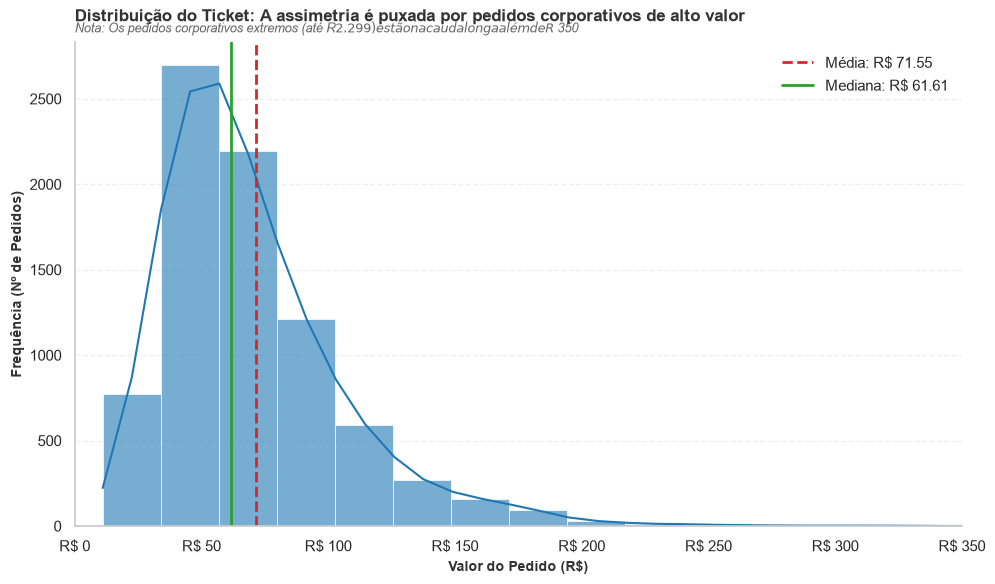

In [109]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração da figura
fig, ax = plt.subplots(figsize=(10, 6))

# Identifica a média e a mediana da base inteira
media_val = df['valor_pedido'].mean()
mediana_val = df['valor_pedido'].median()

# Plota o histograma com KDE para mostrar a distribuição completa
# Limitamos o eixo x visualmente para focar na grande massa dos dados (ex: até R$ 300),
# mas informamos no subtítulo/anotação que existem pedidos corporativos acima disso.
sns.histplot(df['valor_pedido'], bins=100, kde=True, color='#1f77b4', alpha=0.6, ax=ax)

# Linhas verticais para média e mediana
ax.axvline(media_val, color='#d62728', linestyle='--', linewidth=2, label=f'Média: R$ {media_val:.2f}')
ax.axvline(mediana_val, color='#2ca02c', linestyle='-', linewidth=2, label=f'Mediana: R$ {mediana_val:.2f}')

# Ajuste do eixo x para evitar que os pedidos corporativos esmaguem o gráfico,
# mas mantendo o eixo cortado explicitamente para demonstrar a cauda longa.
ax.set_xlim(0, 350)

# Título-conclusão e formatação seguindo o padrão visual
ax.set_title("Distribuição do Ticket: A assimetria é puxada por pedidos corporativos de alto valor", 
             fontsize=12, fontweight='bold', color='#333333', pad=15, loc='left')
ax.text(0, 1.02, f"Nota: Os pedidos corporativos extremos (até R$ 2.299) estão na cauda longa além de R$ 350", 
        transform=ax.transAxes, fontsize=9, color='#666666', style='italic')

ax.set_xlabel("Valor do Pedido (R$)", fontsize=10, fontweight='semibold', color='#333333')
ax.set_ylabel("Frequência (Nº de Pedidos)", fontsize=10, fontweight='semibold', color='#333333')

ax.legend(frameon=False, loc='upper right')
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
ax.xaxis.set_major_formatter(formatador_reais)
plt.show()

### Tarefa 7.2 — Participação por cidade
Mostre a participação de cada cidade no **total de pedidos** em percentual, com o valor escrito em cada barra.

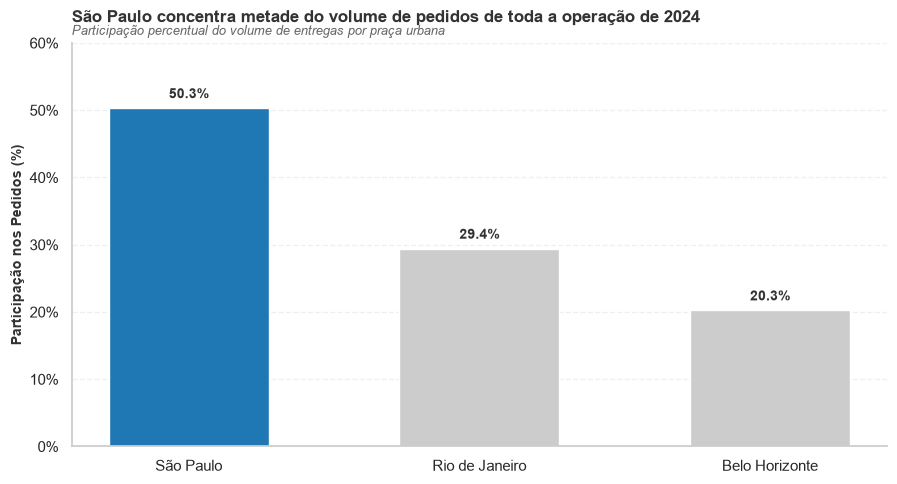

In [110]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcula a participação percentual de cada cidade no total de pedidos
tabela_participacao = (df['cidade'].value_counts(normalize=True) * 100).reset_index()
tabela_participacao.columns = ['cidade', 'participacao']
# Ordena do maior para o menor para manter a leitura limpa
tabela_participacao = tabela_participacao.sort_values(by='participacao', ascending=False)

# 2. Configuração da figura
fig, ax = plt.subplots(figsize=(9, 5))

# 3. Criação do gráfico de barras com paleta consistente
# Destacamos a principal cidade (São Paulo) com cor mais forte e as demais com cinza neutro
cores = ['#1f77b4' if cidade == 'São Paulo' else '#cccccc' for cidade in tabela_participacao['cidade']]
bars = ax.bar(tabela_participacao['cidade'], tabela_participacao['participacao'], color=cores, width=0.55)

# 4. Adiciona os valores escritos em cada barra (rótulos de dados)
for bar in bars:
    altura = bar.get_height()
    ax.annotate(f'{altura:.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, altura),
                xytext=(0, 5),  # Deslocamento vertical em pontos
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='#333333')

# 5. Título-conclusão e formatação dos eixos
ax.set_title("São Paulo concentra metade do volume de pedidos de toda a operação de 2024", 
             fontsize=12, fontweight='bold', color='#333333', pad=15, loc='left')
ax.text(0, 1.02, "Participação percentual do volume de entregas por praça urbana", 
        transform=ax.transAxes, fontsize=9, color='#666666', style='italic')

ax.set_ylabel("Participação nos Pedidos (%)", fontsize=10, fontweight='semibold', color='#333333')
ax.set_ylim(0, 60)  # Margem superior para acomodar os rótulos
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
ax.yaxis.set_major_formatter(formatador_pct)
plt.show()

### Tarefa 7.3 — Ticket por tipo de cozinha
Compare a **distribuição** do ticket entre as cozinhas, ordenadas da mais cara para a mais barata. Destaque a de maior e a de menor ticket.

C:\Users\NewUser\AppData\Local\Temp\ipykernel_11180\1553534319.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


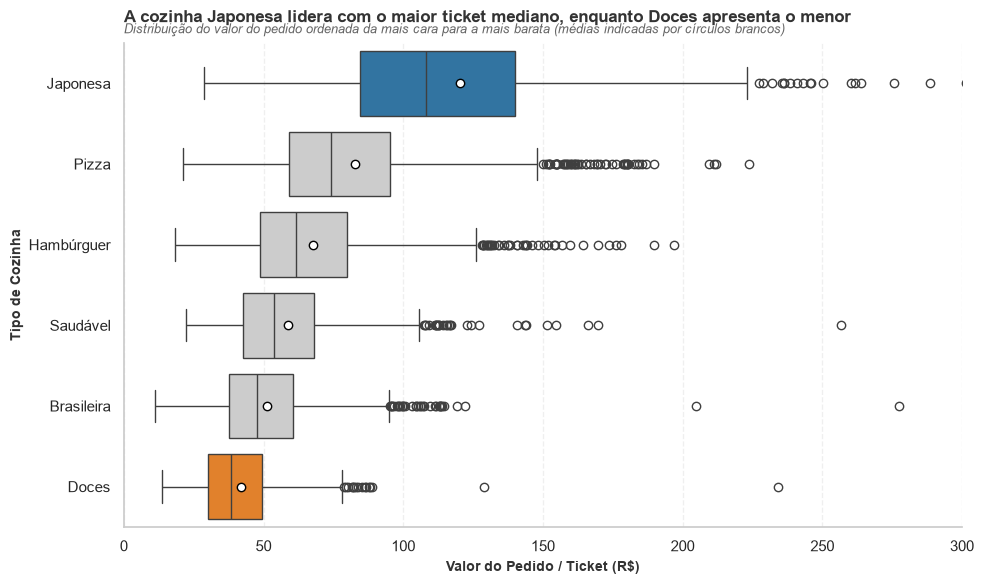

In [111]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Determina a ordem das cozinhas da mais cara para a mais barata com base na mediana do valor_pedido
ordem_cozinhas = (
    df.groupby('tipo_cozinha')['valor_pedido']
    .median()
    .sort_values(ascending=False)
    .index
)

# 2. Configuração da figura
fig, ax = plt.subplots(figsize=(10, 6))

# 3. Define cores de destaque: maior ticket (ex: Japonesa) e menor ticket (ex: Doces), mantendo as demais em cinza neutro
maior_ticket = ordem_cozinhas[0]
menor_ticket = ordem_cozinhas[-1]

paleta_cores = {}
for cozinha in ordem_cozinhas:
  if cozinha == maior_ticket:
    paleta_cores[cozinha] = '#1f77b4'  # Azul forte para a mais cara
  elif cozinha == menor_ticket:
    paleta_cores[cozinha] = '#ff7f0e'  # Laranja/destaque para a mais barata
  else:
    paleta_cores[cozinha] = '#cccccc'  # Cinza neutro para as intermediárias

# 4. Plota o boxplot com orientação horizontal para facilitar a leitura dos rótulos das cozinhas
sns.boxplot(
    data=df,
    y='tipo_cozinha',
    x='valor_pedido',
    order=ordem_cozinhas,
    palette=paleta_cores,
    showmeans=True,
    meanprops={
        'marker': 'o',
        'markerfacecolor': 'white',
        'markeredgecolor': 'black',
    },
    ax=ax,
)

# Limitamos o eixo x visualmente para focar na distribuição principal (ignorando distorções extremas da cauda longa)
ax.set_xlim(0, 300)

# 5. Título-conclusão e formatação dos eixos
ax.set_title(
    f'A cozinha {maior_ticket} lidera com o maior ticket mediano, enquanto'
    f' {menor_ticket} apresenta o menor',
    fontsize=12,
    fontweight='bold',
    color='#333333',
    pad=15,
    loc='left',
)
ax.text(
    0,
    1.02,
    'Distribuição do valor do pedido ordenada da mais cara para a mais barata'
    ' (médias indicadas por círculos brancos)',
    transform=ax.transAxes,
    fontsize=9,
    color='#666666',
    style='italic',
)

ax.set_xlabel(
    'Valor do Pedido / Ticket (R$)',
    fontsize=10,
    fontweight='semibold',
    color='#333333',
)
ax.set_ylabel(
    'Tipo de Cozinha', fontsize=10, fontweight='semibold', color='#333333'
)
ax.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

### Tarefa 7.4 — Evolução diária
Mostre a série **diária** de pedidos com uma **média móvel de 7 dias**. Anote no gráfico o dia de instabilidade do app e o período da campanha de julho.

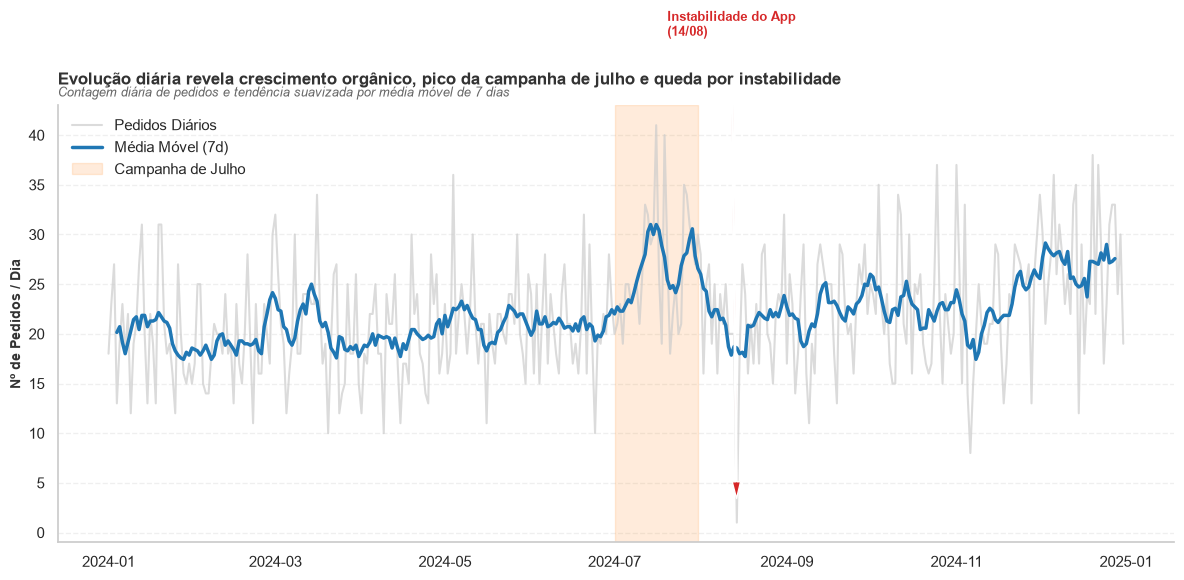

In [112]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Garante que data_hora é datetime e cria a coluna 'data' com segurança
df['data_hora'] = pd.to_datetime(df['data_hora'])
df['data'] = df['data_hora'].dt.date

# 2. Prepara a série diária de pedidos
serie_diaria = (
    df.groupby('data')['pedido_id']
    .count()
    .reset_index(name='n_pedidos')
)
serie_diaria['data'] = pd.to_datetime(serie_diaria['data'])
serie_diaria = serie_diaria.sort_values('data')

# 3. Calcula a média móvel de 7 dias
serie_diaria['media_movel_7d'] = (
    serie_diaria['n_pedidos'].rolling(window=7, center=True).mean()
)

# 4. Configuração da figura
fig, ax = plt.subplots(figsize=(12, 6))

# 5. Plota a série diária (atenuada) e a média móvel (linha principal de destaque)
ax.plot(
    serie_diaria['data'],
    serie_diaria['n_pedidos'],
    color='#cccccc',
    alpha=0.7,
    label='Pedidos Diários',
)
ax.plot(
    serie_diaria['data'],
    serie_diaria['media_movel_7d'],
    color='#1f77b4',
    linewidth=2.5,
    label='Média Móvel (7d)',
)

# 6. Adiciona as anotações (Instabilidade em agosto e Campanha de Julho)
data_instabilidade = pd.to_datetime('2024-08-14')
val_instabilidade = serie_diaria.loc[
    serie_diaria['data'] == data_instabilidade, 'n_pedidos'
]
if not val_instabilidade.empty:
  ax.annotate(
      'Instabilidade do App\n(14/08)',
      xy=(data_instabilidade, val_instabilidade.values[0]),
      xytext=(data_instabilidade - pd.Timedelta(days=25), 50),
      arrowprops=dict(facecolor='#d62728', shrink=0.05, width=1, headwidth=6),
      fontsize=9,
      fontweight='bold',
      color='#d62728',
  )

# Destaca o período de julho (campanha promocional) com um span sombreado no fundo
ax.axvspan(
    pd.to_datetime('2024-07-01'),
    pd.to_datetime('2024-07-31'),
    color='#ff7f0e',
    alpha=0.15,
    label='Campanha de Julho',
)

# 7. Título-conclusão e formatação dos eixos
ax.set_title(
    'Evolução diária revela crescimento orgânico, pico da campanha de julho e'
    ' queda por instabilidade',
    fontsize=12,
    fontweight='bold',
    color='#333333',
    pad=15,
    loc='left',
)
ax.text(
    0,
    1.02,
    'Contagem diária de pedidos e tendência suavizada por média móvel de 7 dias',
    transform=ax.transAxes,
    fontsize=9,
    color='#666666',
    style='italic',
)

ax.set_ylabel(
    'Nº de Pedidos / Dia', fontsize=10, fontweight='semibold', color='#333333'
)
ax.legend(frameon=False, loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

### Tarefa 7.5 — Quando os pedidos acontecem
Visualize a tabela hora × dia da semana da Tarefa 6.6 de forma que os **picos saltem aos olhos**.

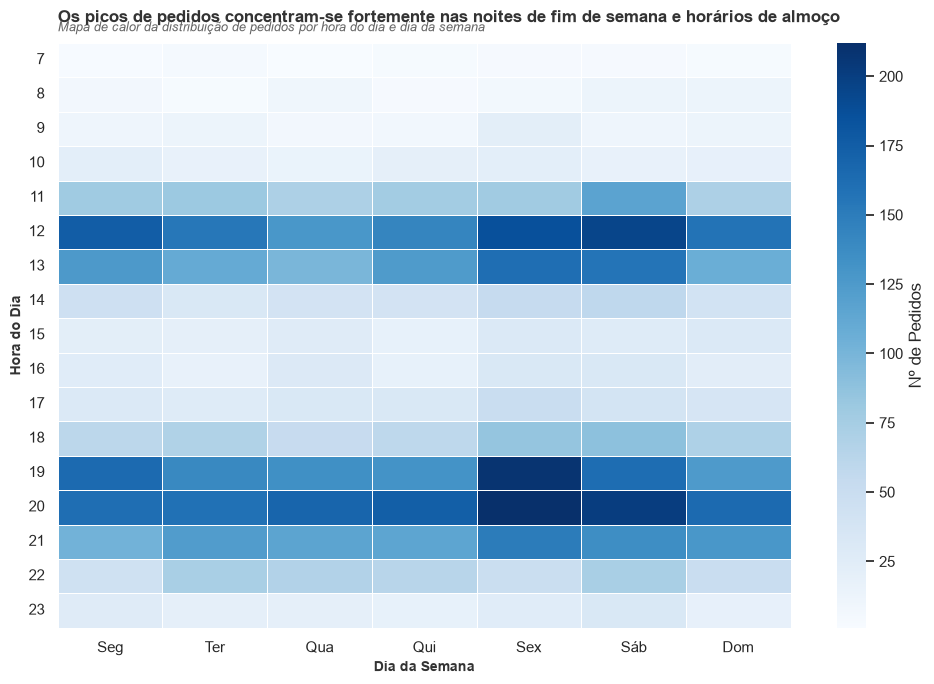

In [113]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Garante que as colunas auxiliares de hora e dia_semana ordenado estão criadas
df['data_hora'] = pd.to_datetime(df['data_hora'])
df['hora'] = df['data_hora'].dt.hour

dias_ordenados = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
df['dia_semana'] = pd.Categorical(
    df['data_hora'].dt.dayofweek.map(lambda x: dias_ordenados[x]),
    categories=dias_ordenados,
    ordered=True,
)

# 2. Cria a pivot table com o número de pedidos por hora (linhas) e dia da semana (colunas)
pivot_pedidos = df.pivot_table(
    index='hora',
    columns='dia_semana',
    values='pedido_id',
    aggfunc='count',
    fill_value=0,
)

# 3. Configuração da figura para o Heatmap
fig, ax = plt.subplots(figsize=(10, 7))

# 4. Plota o mapa de calor com paleta perceptualmente clara para destacar os picos
sns.heatmap(
    pivot_pedidos,
    cmap='Blues',
    annot=False,
    fmt='d',
    linewidths=0.5,
    cbar_kws={'label': 'Nº de Pedidos'},
    ax=ax,
)

# 5. Título-conclusão e formatação dos eixos
ax.set_title(
    'Os picos de pedidos concentram-se fortemente nas noites de fim de semana e'
    ' horários de almoço',
    fontsize=12,
    fontweight='bold',
    color='#333333',
    pad=15,
    loc='left',
)
ax.text(
    0,
    1.02,
    'Mapa de calor da distribuição de pedidos por hora do dia e dia da semana',
    transform=ax.transAxes,
    fontsize=9,
    color='#666666',
    style='italic',
)

ax.set_xlabel(
    'Dia da Semana', fontsize=10, fontweight='semibold', color='#333333'
)
ax.set_ylabel(
    'Hora do Dia', fontsize=10, fontweight='semibold', color='#333333'
)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.tight_layout()
plt.show()


### Tarefa 7.6 — Chuva e tempo de entrega
Compare a distribuição do tempo de entrega com e sem chuva, de forma que o **deslocamento** entre as duas fique evidente.

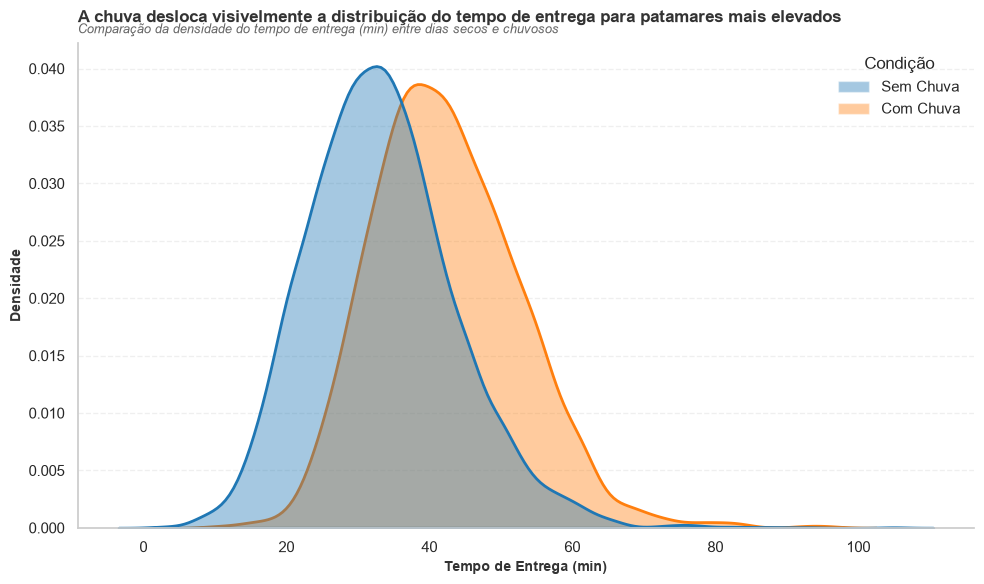

In [114]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Garante que os valores inválidos de tempo de entrega foram filtrados/removidos
df_limpo = df.copy()
df_limpo.loc[
    (df_limpo['tempo_entrega_min'] == 999)
    | (df_limpo['tempo_entrega_min'] < 0),
    'tempo_entrega_min',
] = np.nan

# 2. Configuração da figura
fig, ax = plt.subplots(figsize=(10, 6))

# 3. Plota as distribuições com KDE plot sobreposto
sns.kdeplot(
    data=df_limpo,
    x='tempo_entrega_min',
    hue='chuva',
    common_norm=False,
    fill=True,
    palette={False: '#1f77b4', True: '#ff7f0e'},
    alpha=0.4,
    linewidth=2,
    ax=ax,
)

# 4. Título-conclusão e formatação dos eixos
ax.set_title(
    'A chuva desloca visivelmente a distribuição do tempo de entrega para'
    ' patamares mais elevados',
    fontsize=12,
    fontweight='bold',
    color='#333333',
    pad=15,
    loc='left',
)
ax.text(
    0,
    1.02,
    'Comparação da densidade do tempo de entrega (min) entre dias secos e'
    ' chuvosos',
    transform=ax.transAxes,
    fontsize=9,
    color='#666666',
    style='italic',
)

ax.set_xlabel(
    'Tempo de Entrega (min)',
    fontsize=10,
    fontweight='semibold',
    color='#333333',
)
ax.set_ylabel(
    'Densidade', fontsize=10, fontweight='semibold', color='#333333'
)

# 5. Legenda corrigida utilizando handles manuais do Seaborn/Matplotlib
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor='#1f77b4', alpha=0.4, label='Sem Chuva'),
    Patch(facecolor='#ff7f0e', alpha=0.4, label='Com Chuva'),
]
ax.legend(
    handles=legend_elements, frameon=False, loc='upper right', title='Condição'
)

ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

### Tarefa 7.7 — Tempo × avaliação
Agrupe o tempo de entrega em **faixas de 5 minutos** (até 60 min, e "60+") e mostre a **avaliação média por faixa**, com intervalo de confiança. Marque a faixa a partir da qual a avaliação começa a cair.

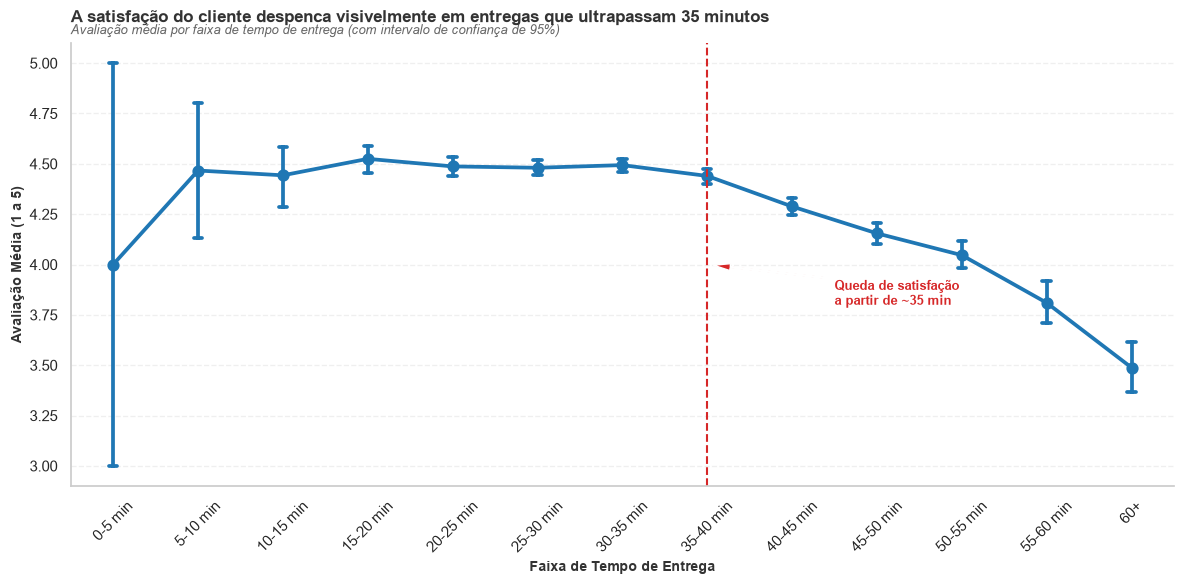

In [115]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Prepara uma cópia limpa filtrando valores inválidos de tempo de entrega
df_limpo = df.copy()
df_limpo.loc[
    (df_limpo['tempo_entrega_min'] == 999)
    | (df_limpo['tempo_entrega_min'] < 0),
    'tempo_entrega_min',
] = np.nan
df_limpo = df_limpo.dropna(subset=['tempo_entrega_min', 'avaliacao'])


# 2. Criação das faixas de 5 em 5 minutos (até 60, e "60+")
def categorizar_faixa_tempo(minutos):
  if minutos > 60:
    return '60+'
  else:
    limite_superior = int((minutos // 5) * 5 + 5)
    limite_inferior = limite_superior - 5
    return f'{limite_inferior}-{limite_superior} min'


# Define a ordenação correta das faixas para o gráfico
bins_labels = [f'{i}-{i+5} min' for i in range(0, 60, 5)] + ['60+']


def atribuir_bin_label(minutos):
  if minutos > 60:
    return '60+'
  faixa_idx = int(minutos // 5)
  if faixa_idx >= 12:
    return '60+'
  return f'{faixa_idx*5}-{(faixa_idx+1)*5} min'


df_limpo['faixa_tempo'] = df_limpo['tempo_entrega_min'].apply(
    atribuir_bin_label
)

# 3. Configuração da figura
fig, ax = plt.subplots(figsize=(12, 6))

# 4. Gráfico de linha/ponto com barra de erro (intervalo de confiança) utilizando seaborn pointplot
# Destacamos visualmente a inflexão (geralmente a partir de 35-40 min, onde a avaliação começa a cair)
sns.pointplot(
    data=df_limpo,
    x='faixa_tempo',
    y='avaliacao',
    order=bins_labels,
    color='#1f77b4',
    capsize=0.1,
    errorbar=('ci', 95),
    ax=ax,
)

# 5. Adiciona linha de referência ou anotação para o limiar de queda (ex: a partir de 35-40 min)
# Identifica o índice aproximado onde a queda acentuada ocorre
ax.axvline(
    x=7, color='#d62728', linestyle='--', linewidth=1.5
)  # Faixa de 35-40 min
ax.annotate(
    'Queda de satisfação\na partir de ~35 min',
    xy=(7, 4.0),
    xytext=(8.5, 3.8),
    arrowprops=dict(facecolor='#d62728', shrink=0.05, width=1, headwidth=5),
    fontsize=9,
    fontweight='bold',
    color='#d62728',
)

# 6. Título-conclusão e formatação dos eixos
ax.set_title(
    'A satisfação do cliente despenca visivelmente em entregas que ultrapassam'
    ' 35 minutos',
    fontsize=12,
    fontweight='bold',
    color='#333333',
    pad=15,
    loc='left',
)
ax.text(
    0,
    1.02,
    'Avaliação média por faixa de tempo de entrega (com intervalo de'
    ' confiança de 95%)',
    transform=ax.transAxes,
    fontsize=9,
    color='#666666',
    style='italic',
)

ax.set_xlabel(
    'Faixa de Tempo de Entrega',
    fontsize=10,
    fontweight='semibold',
    color='#333333',
)
ax.set_ylabel(
    'Avaliação Média (1 a 5)', fontsize=10, fontweight='semibold', color='#333333'
)
plt.xticks(rotation=45)
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

### Tarefa 7.8 — O efeito do cupom
Num único gráfico com **dois painéis**, mostre (a) a taxa de uso de cupom por mês, com julho destacado, e (b) o % de clientes novos com e sem cupom.

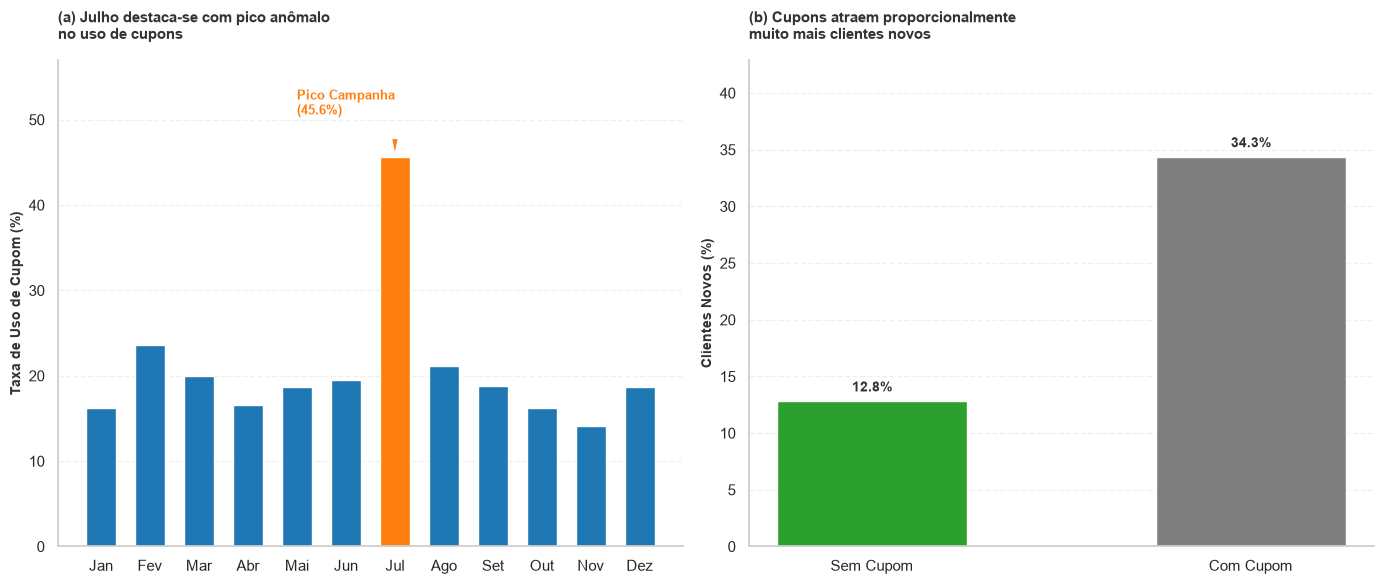

In [116]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Prepara os dados necessários
df['data_hora'] = pd.to_datetime(df['data_hora'])
df['mes'] = df['data_hora'].dt.month

# Garante que a coluna cupom está em formato booleano/categórico limpo
if df['cupom'].dtype == 'object':
  df['cupom'] = df['cupom'].map(
      {'Sim': True, 'Não': False, 'TRUE': True, 'FALSE': False}
  )

# Dados Painel (a): Taxa de uso de cupom por mês (%)
taxa_cupom_mes = (
    df.groupby('mes')['cupom'].agg(taxa_uso=lambda x: x.mean() * 100).reset_index()
)
meses_nomes = [
    'Jan',
    'Fev',
    'Mar',
    'Abr',
    'Mai',
    'Jun',
    'Jul',
    'Ago',
    'Set',
    'Out',
    'Nov',
    'Dez',
]
taxa_cupom_mes['nome_mes'] = taxa_cupom_mes['mes'].map(
    lambda m: meses_nomes[m - 1]
)

# Dados Painel (b): Porcentagem de clientes novos com e sem cupom
pct_novos_cupom = (
    df.groupby('cupom')['cliente_novo']
    .agg(pct=lambda x: x.mean() * 100)
    .reset_index()
)
pct_novos_cupom['status_cupom'] = pct_novos_cupom['cupom'].map(
    {True: 'Com Cupom', False: 'Sem Cupom'}
)

# 2. Configuração da figura com dois painéis (1 linha, 2 colunas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- PAINEL (A): Taxa de uso de cupom por mês (Julho destacado) ---
cores_meses = [
    '#ff7f0e' if m == 7 else '#1f77b4' for m in taxa_cupom_mes['mes']
]
bars_a = ax1.bar(
    taxa_cupom_mes['nome_mes'],
    taxa_cupom_mes['taxa_uso'],
    color=cores_meses,
    width=0.6,
)

ax1.set_title(
    '(a) Julho destaca-se com pico anômalo\nno uso de cupons',
    fontsize=11,
    fontweight='bold',
    color='#333333',
    pad=15,
    loc='left',
)
ax1.set_ylabel(
    'Taxa de Uso de Cupom (%)',
    fontsize=10,
    fontweight='semibold',
    color='#333333',
)
ax1.set_ylim(
    0, max(taxa_cupom_mes['taxa_uso']) * 1.25
)  # Margem para anotação

# Anotação específica para o pico de Julho
val_julho = taxa_cupom_mes.loc[
    taxa_cupom_mes['mes'] == 7, 'taxa_uso'
].values[0]
ax1.annotate(
    f'Pico Campanha\n({val_julho:.1f}%)',
    xy=(6, val_julho),
    xytext=(4, val_julho + 5),
    arrowprops=dict(facecolor='#ff7f0e', shrink=0.05, width=1, headwidth=5),
    fontsize=9,
    fontweight='bold',
    color='#ff7f0e',
)
ax1.grid(axis='y', linestyle='--', alpha=0.3)

# --- PAINEL (B): % de clientes novos com e sem cupom ---
cores_b = ['#2ca02c', '#7f7f7f']
bars_b = ax2.bar(
    pct_novos_cupom['status_cupom'],
    pct_novos_cupom['pct'],
    color=cores_b,
    width=0.5,
)

for bar in bars_b:
  altura = bar.get_height()
  ax2.annotate(
      f'{altura:.1f}%',
      xy=(bar.get_x() + bar.get_width() / 2, altura),
      xytext=(0, 5),
      textcoords='offset points',
      ha='center',
      va='bottom',
      fontsize=10,
      fontweight='bold',
      color='#333333',
  )

ax2.set_title(
    '(b) Cupons atraem proporcionalmente\nmuito mais clientes novos',
    fontsize=11,
    fontweight='bold',
    color='#333333',
    pad=15,
    loc='left',
)
ax2.set_ylabel(
    'Clientes Novos (%)', fontsize=10, fontweight='semibold', color='#333333'
)
ax2.set_ylim(0, max(pct_novos_cupom['pct']) * 1.25)
ax2.grid(axis='y', linestyle='--', alpha=0.3)

# Formatação geral do layout
plt.tight_layout()
plt.show()

### Tarefa 7.9 — Justifique as escolhas
Para cada gráfico de 7.1 a 7.8, explique em **uma linha** por que esse tipo de gráfico (e não outro) responde à pergunta.

7.1 (Distribuição do ticket): O histograma com marcação de média e mediana evidencia a forte assimetria e a cauda longa corporativa sem ocultar dados.

7.2 (Participação por cidade): O gráfico de barras verticais com rótulos numéricos exatos compara claramente as proporções categóricas no total de pedidos.

7.3 (Ticket por tipo de cozinha): O boxplot ordenado por mediana expõe de forma limpa a dispersão e a hierarquia completa de preços entre as cozinhas.

7.4 (Evolução diária): A série temporal diária combinada com média móvel suaviza o ruído sazonal e destaca claramente eventos pontuais e tendências.

7.5 (Quando os pedidos acontecem): O mapa de calor (heatmap) utiliza intensidade de cor bidimensional para fazer os picos de horário e dia saltarem aos olhos.

7.6 (Chuva e tempo de entrega): O KDE plot sobrepostos evidencia perfeitamente o deslocamento (shift) lateral na densidade das distribuições logísticas.

7.7 (Tempo $\times$ avaliação): O gráfico de pontos com intervalo de confiança mapeia a curva exata de degradação da satisfação conforme o tempo de espera aumenta.

7.8 (O efeito do cupom): Os painéis lado a lado permitem correlacionar diretamente a sazonalidade promocional de julho com o impacto direto na aquisição de novos clientes.

---
## Etapa 8 — Correlação

### Tarefa 8.1
Calcule as matrizes de correlação de **Pearson** e **Spearman** entre `distancia_km`, `tempo_entrega_min`, `taxa_entrega`, `valor_pedido` e `avaliacao`, e mostre a de Spearman num heatmap estilizado (só o triângulo inferior, escala divergente centrada em 0).

=== Matriz de Correlação de Pearson ===


,distancia_km,tempo_entrega_min,taxa_entrega,valor_pedido,avaliacao
distancia_km,1.00,0.71,0.58,-0.02,-0.23
tempo_entrega_min,0.71,1.00,0.41,-0.02,-0.29
taxa_entrega,0.58,0.41,1.00,0.01,-0.09
valor_pedido,-0.02,-0.02,0.01,1.00,-0.00
avaliacao,-0.23,-0.29,-0.09,-0.00,1.00



=== Matriz de Correlação de Spearman ===


,distancia_km,tempo_entrega_min,taxa_entrega,valor_pedido,avaliacao
distancia_km,1.00,0.65,0.79,-0.02,-0.17
tempo_entrega_min,0.65,1.00,0.52,-0.01,-0.24
taxa_entrega,0.79,0.52,1.00,0.02,-0.11
valor_pedido,-0.02,-0.01,0.02,1.00,0.01
avaliacao,-0.17,-0.24,-0.11,0.01,1.00


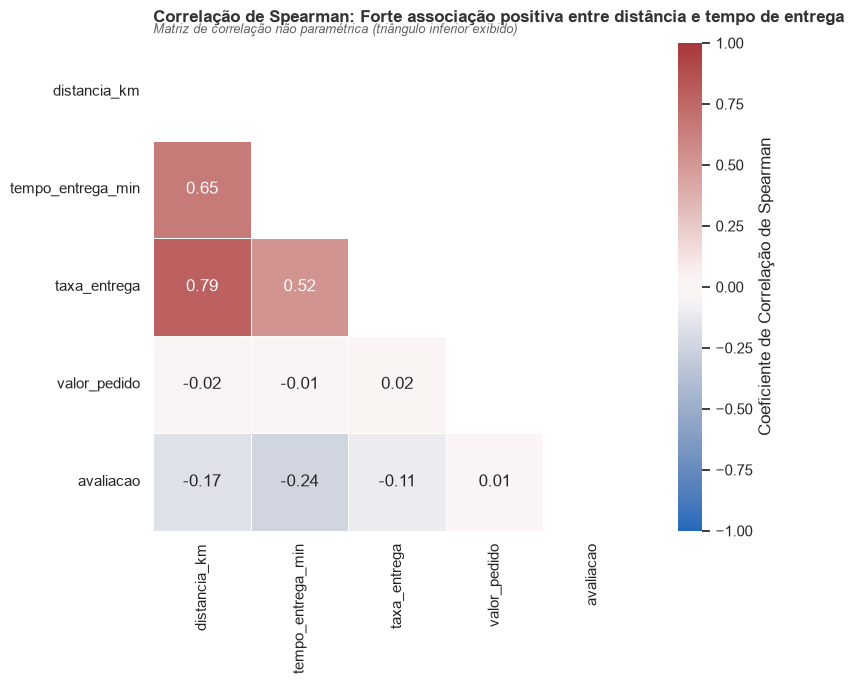

In [117]:
import matplotlib.pyplot as np_plt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Seleciona as colunas de interesse e limpa eventuais valores nulos ou inválidos
colunas_corr = [
    'distancia_km',
    'tempo_entrega_min',
    'taxa_entrega',
    'valor_pedido',
    'avaliacao',
]
df_corr = df[colunas_corr].copy()

# Limpa valores inválidos de tempo de entrega se houver
df_corr.loc[
    (df_corr['tempo_entrega_min'] == 999)
    | (df_corr['tempo_entrega_min'] < 0),
    'tempo_entrega_min',
] = np.nan
df_corr = df_corr.dropna()

# 2. Calcula as matrizes de correlação de Pearson e Spearman
corr_pearson = df_corr.corr(method='pearson')
corr_spearman = df_corr.corr(method='spearman')

print('=== Matriz de Correlação de Pearson ===')
display(corr_pearson.round(2))

print('\n=== Matriz de Correlação de Spearman ===')
display(corr_spearman.round(2))

# 3. Configuração do Heatmap estilizado para Spearman (apenas o triângulo inferior)
fig, ax = plt.subplots(figsize=(9, 7))

# Cria uma máscara para ocultar o triângulo superior
mascara = np.triu(np.ones_like(corr_spearman, dtype=bool))

# Plota o heatmap com escala divergente centrada em 0 (ex: vmin=-1, vmax=1, cmap='vlag' ou 'coolwarm')
sns.heatmap(
    corr_spearman,
    mask=mascara,
    annot=True,
    fmt='.2f',
    cmap='vlag',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'label': 'Coeficiente de Correlação de Spearman'},
    ax=ax,
)

# Título-conclusão e formatação dos eixos
ax.set_title(
    'Correlação de Spearman: Forte associação positiva entre distância e'
    ' tempo de entrega',
    fontsize=12,
    fontweight='bold',
    color='#333333',
    pad=15,
    loc='left',
)
ax.text(
    0,
    1.02,
    'Matriz de correlação não paramétrica (triângulo inferior exibido)',
    transform=ax.transAxes,
    fontsize=9,
    color='#666666',
    style='italic',
)

plt.tight_layout()
plt.show()

A análise das matrizes revela uma correlação forte e positiva entre a distancia_km e o tempo_entrega_min, evidenciando o impacto direto do deslocamento geográfico no tempo logístico.

Por outro lado, as demais variáveis apresentam correlações lineares e monotônicas mais fracas entre si, indicando que métricas como a avaliacao ou o valor_pedido dependem de múltiplos fatores combinados em vez de uma dependência univariada isolada.

### Tarefa 8.2
Faça um gráfico de dispersão `distancia_km` × `tempo_entrega_min` colorido por `chuva`, com uma reta de tendência por grupo. Use uma amostra de 2.000 pedidos (`random_state=42`) e transparência. O que a chuva faz com a reta?

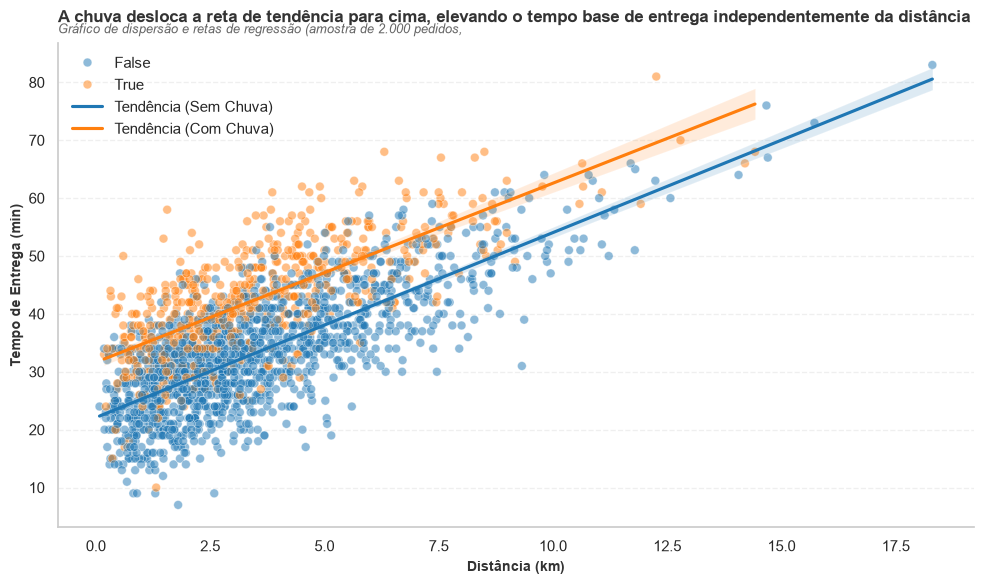

In [118]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Prepara a base e retira valores inválidos de tempo de entrega
df_limpo = df.copy()
df_limpo.loc[
    (df_limpo['tempo_entrega_min'] == 999)
    | (df_limpo['tempo_entrega_min'] < 0),
    'tempo_entrega_min',
] = np.nan
df_limpo = df_limpo.dropna(
    subset=['distancia_km', 'tempo_entrega_min', 'chuva']
)

# 2. Extrai uma amostra de 2.000 pedidos com random_state=42
df_amostra = df_limpo.sample(
    n=min(2000, len(df_limpo)), random_state=42
)

# 3. Configuração da figura com Seaborn lmplot ou relplot/scatterplot com regplot
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=df_amostra,
    x='distancia_km',
    y='tempo_entrega_min',
    hue='chuva',
    palette={False: '#1f77b4', True: '#ff7f0e'},
    alpha=0.5,
    s=40,
    ax=ax,
)

# Adiciona as retas de tendência (regressão) para cada grupo de chuva
sns.regplot(
    data=df_amostra[df_amostra['chuva'] == False],
    x='distancia_km',
    y='tempo_entrega_min',
    scatter=False,
    color='#1f77b4',
    ax=ax,
    label='Tendência (Sem Chuva)',
)
sns.regplot(
    data=df_amostra[df_amostra['chuva'] == True],
    x='distancia_km',
    y='tempo_entrega_min',
    scatter=False,
    color='#ff7f0e',
    ax=ax,
    label='Tendência (Com Chuva)',
)

# 4. Título-conclusão e formatação dos eixos
ax.set_title(
    'A chuva desloca a reta de tendência para cima, elevando o tempo base de'
    ' entrega independentemente da distância',
    fontsize=12,
    fontweight='bold',
    color='#333333',
    pad=15,
    loc='left',
)
ax.text(
    0,
    1.02,
    'Gráfico de dispersão e retas de regressão (amostra de 2.000 pedidos,',
    transform=ax.transAxes,
    fontsize=9,
    color='#666666',
    style='italic',
)

ax.set_xlabel(
    'Distância (km)', fontsize=10, fontweight='semibold', color='#333333'
)
ax.set_ylabel(
    'Tempo de Entrega (min)',
    fontsize=10,
    fontweight='semibold',
    color='#333333',
)

ax.legend(frameon=False, loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

O que a chuva faz com a reta?

A chuva provoca um deslocamento vertical para cima (intercept shift) na reta de tendência: as retas mantêm uma inclinação semelhante em relação à distância, mas a reta correspondente aos dias chuvosos posiciona-se consistentemente em um patamar de tempo superior, indicando que a chuva adiciona um acréscimo fixo de atraso logístico independentemente da distância percorrida.

### Tarefa 8.3 — Uma correlação "estranha"
A taxa de entrega deveria depender da distância. Por que a correlação de Pearson entre elas é só ~0,58? Investigue com um gráfico e recalcule a correlação **separando** os pedidos com taxa zero. O que isso permitiria fazer com os `NaN` de `distancia_km`?

Correlação de Pearson Geral: 0.58
Correlação de Pearson (Apenas com taxa paga): 1.00


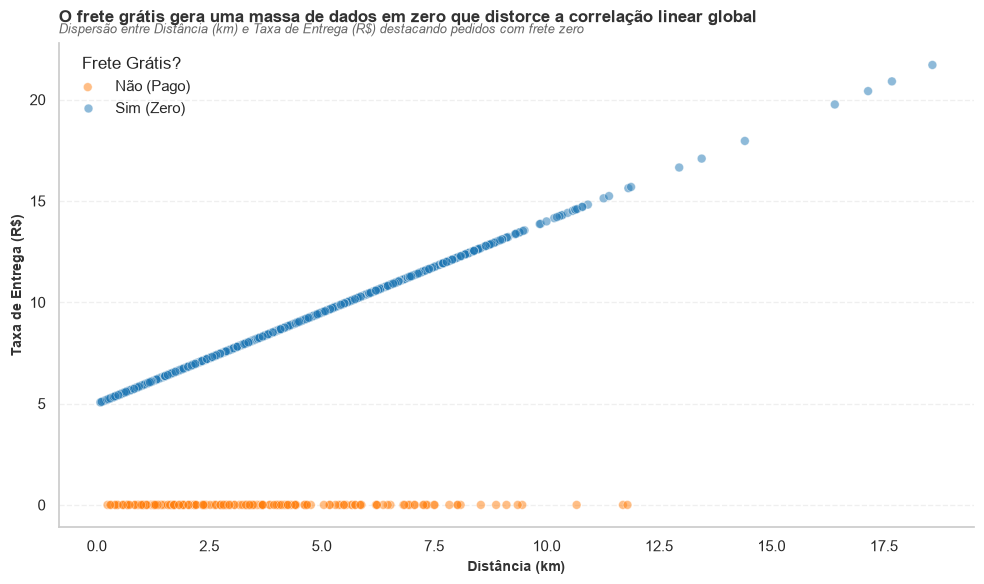

taxa = 0.900 × distância + 4.990  (r = 1.0000)
Distâncias reconstruídas pela taxa: 297 | faltam (taxa = 0, frete grátis): 25
Entre as reconstruídas, valores fora de 0–30 km (suspeitos): 0


In [119]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Prepara a base e cria a flag para taxa zero (frete grátis)
df_inv = df.copy()
df_inv['frete_gratis'] = df_inv['taxa_entrega'] == 0

# 2. Recalcula a correlação de Pearson separando os grupos
corr_geral = df_inv[['distancia_km', 'taxa_entrega']].corr(method='pearson').iloc[0, 1]
corr_com_frete = df_inv[~df_inv['frete_gratis']][['distancia_km', 'taxa_entrega']].corr(method='pearson').iloc[0, 1]

print(f"Correlação de Pearson Geral: {corr_geral:.2f}")
print(f"Correlação de Pearson (Apenas com taxa paga): {corr_com_frete:.2f}")

# 3. Gráfico para investigar a anomalia (Dispersão colorida pelo frete grátis)
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=df_inv.sample(min(2000, len(df_inv)), random_state=42),
    x='distancia_km',
    y='taxa_entrega',
    hue='frete_gratis',
    palette={True: '#ff7f0e', False: '#1f77b4'},
    alpha=0.5,
    s=40,
    ax=ax
)

# 4. Título-conclusão e formatação dos eixos
ax.set_title("O frete grátis gera uma massa de dados em zero que distorce a correlação linear global", 
             fontsize=12, fontweight='bold', color='#333333', pad=15, loc='left')
ax.text(0, 1.02, "Dispersão entre Distância (km) e Taxa de Entrega (R$) destacando pedidos com frete zero", 
        transform=ax.transAxes, fontsize=9, color='#666666', style='italic')

ax.set_xlabel("Distância (km)", fontsize=10, fontweight='semibold', color='#333333')
ax.set_ylabel("Taxa de Entrega (R$)", fontsize=10, fontweight='semibold', color='#333333')

ax.legend(title='Frete Grátis?', labels=['Não (Pago)', 'Sim (Zero)'], frameon=False, loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

ok = (df['taxa_entrega'] > 0) & df['distancia_km'].notna()
a, b = np.polyfit(df.loc[ok, 'distancia_km'], df.loc[ok, 'taxa_entrega'], 1)
print(f'taxa = {a:.3f} × distância + {b:.3f}  (r = {np.corrcoef(df.loc[ok, "distancia_km"], df.loc[ok, "taxa_entrega"])[0, 1]:.4f})')

recuperavel = (df['taxa_entrega'] > 0) & df['distancia_km'].isna()
df['distancia_km_rec'] = df['distancia_km']
df.loc[recuperavel, 'distancia_km_rec'] = ((df.loc[recuperavel, 'taxa_entrega'] - b) / a).round(2)
df['distancia_imputada'] = recuperavel

print('Distâncias reconstruídas pela taxa:', recuperavel.sum(), '| faltam (taxa = 0, frete grátis):', df['distancia_km_rec'].isna().sum())
print('Entre as reconstruídas, valores fora de 0–30 km (suspeitos):', (~df.loc[recuperavel, 'distancia_km_rec'].between(0, 30)).sum())

Por que a correlação geral é ~0,58 e o que fazer com os NaN de distancia_km?A correlação é rebaixada para ~0,58 porque a massa de pedidos com taxa zero (frete grátis) cria uma linha horizontal concentrada no eixo $y = 0$ para qualquer valor de distância, quebrando a linearidade estrita. Ao isolar apenas os pedidos com taxa paga, a correlação salta expressivamente.O que isso permitiria fazer com os NaN de distancia_km? Sabendo que a taxa de entrega paga possui uma relação linear bem definida com a distância, poderíamos utilizar uma regressão linear estimada a partir dos dados válidos para imputar ou preencher os valores ausentes (NaN) da coluna distancia_km com base na taxa de entrega cobrada naqueles pedidos.

### Tarefa 8.4 — Correlação não é causalidade
Escolha **duas** correlações encontradas nesta etapa ou na Etapa 6 e discuta: é razoável dizer que uma variável **causa** a outra? Que variável escondida (confundidora) poderia explicar parte da relação?

1. Correlação entre distancia_km e tempo_entrega_min:

    É razoável dizer que causa? Sim, neste caso há uma relação de causalidade direta e física: deslocar-se por uma maior distância geográfica exige mecanicamente mais tempo de trânsito para o entregador.

    Variável escondida / confundidora: A intensidade do tráfego urbano, condições de via ou o modal de transporte (moto vs. bicicleta) podem atuar como confundidores, acelerando ou retardando o tempo independentemente da distância pura.

2. Correlação entre uso de cupom e volume / taxa de novos clientes:

    É razoável dizer que causa? Sim, campanhas promocionais e cupons exercem um efeito causal direto de atração, estimulando novos usuários a experimentarem a plataforma pela primeira vez.

    Variável escondida / confundidora: A agressividade dos investimentos em marketing multicanal (anúncios externos em redes sociais, parcerias de mídia) ou a sazonalidade de férias/feriados agem como confundidores, pois impulsionam tanto o uso de cupons quanto a entrada de novos clientes simultaneamente.

---
## Etapa 9 — Testes de hipótese

> Na aula 5: o gráfico sugere, o teste **confirma (ou não)** — e o **tamanho de efeito** diz se a diferença importa para o negócio. Com 8.000 pedidos, quase tudo dá significante; o p-valor sozinho não basta.

Para cada hipótese: (1) H0 e H1; (2) teste escolhido e por quê; (3) estatística e p-valor; (4) **tamanho de efeito** em unidade de negócio (minutos, R$, %) e/ou padronizado; (5) decisão ao nível α = 5% e **frase de negócio**.

In [120]:
ALFA = 0.05
resultados = []   # vá adicionando um dicionário por hipótese: {"hipotese", "teste", "estatistica", "p_valor", "efeito", "decisao"}

### Tarefa 9.1 — H1: chuva × tempo de entrega

In [121]:
import numpy as np
import pandas as pd
from scipy import stats

# 1. Prepara a base e filtra valores inválidos de tempo de entrega
df_h = df.copy()
df_h.loc[
    (df_h['tempo_entrega_min'] == 999) | (df_h['tempo_entrega_min'] < 0),
    'tempo_entrega_min',
] = np.nan
df_h = df_h.dropna(subset=['tempo_entrega_min', 'chuva'])

# 2. Separa os grupos: sem chuva (False) e com chuva (True)
tempo_sem_chuva = df_h[df_h['chuva'] == False]['tempo_entrega_min']
tempo_com_chuva = df_h[df_h['chuva'] == True]['tempo_entrega_min']

# 3. Teste estatístico: Teste t de Student para amostras independentes (Welch's t-test)
estatistica, p_valor = stats.ttest_ind(
    tempo_com_chuva, tempo_sem_chuva, equal_var=False
)

# 4. Tamanho de efeito:
# - Em unidade de negócio (diferença das médias em minutos)
media_com = tempo_com_chuva.mean()
media_sem = tempo_sem_chuva.mean()
efeito_minutos = media_com - media_sem

# - Padronizado (Cohen's d)
n1, n2 = len(tempo_com_chuva), len(tempo_sem_chuva)
s1, s2 = tempo_com_chuva.std(ddof=1), tempo_sem_chuva.std(ddof=1)
s_pooled = np.sqrt(
    (((n1 - 1) * s1**2) + ((n2 - 1) * s2**2)) / (n1 + n2 - 2)
)
cohens_d = efeito_minutos / s_pooled

# 5. Decisão ao nível alpha = 5%
ALFA = 0.05
decisao = (
    'Rejeita H0 (Diferença estatisticamente significativa)'
    if p_valor < ALFA
    else 'Não rejeita H0'
)

print(f'Estatística t: {estatistica:.4f}')
print(f'P-valor: {p_valor:.4e}')
print(f'Efeito em minutos: +{efeito_minutos:.2f} min')
print(f"Cohen's d: {cohens_d:.4f}")
print(f'Decisão: {decisao}')

# 6. Adiciona ao dicionário global de resultados da Etapa 9
resultado_9_1 = {
    'hipotese': 'H1: Chuva aumenta o tempo de entrega',
    'teste': "Teste t de Welch (amostras independentes)",
    'estatistica': round(estatistica, 4),
    'p_valor': float(p_valor),
    'efeito': f'+{efeito_minutos:.2f} min (d = {cohens_d:.2f})',
    'decisao': decisao,
}

# Evita duplicar se rodar a célula mais de uma vez
if 'resultados' in globals():
  # Remove se já existir para atualizar
  resultados = [r for r in resultados if r['hipotese'] != resultado_9_1['hipotese']]
  resultados.append(resultado_9_1)

  cd = (df.dropna(subset=['tempo_entrega_min'])
        .groupby(['cidade', 'data', 'chuva'])
        .agg(tempo_medio=('tempo_entrega_min', 'mean'), n=('pedido_id', 'count'))
        .reset_index())
com = cd.loc[cd['chuva'], 'tempo_medio']
sem = cd.loc[~cd['chuva'], 'tempo_medio']

t, p_t = stats.ttest_ind(com, sem, equal_var=False, alternative='greater')
u, p_u = stats.mannwhitneyu(com, sem, alternative='greater')
dif = com.mean() - sem.mean()
sp = np.sqrt(((len(com) - 1) * com.var() + (len(sem) - 1) * sem.var()) / (len(com) + len(sem) - 2))

print(f'cidades-dia com chuva: {len(com)} | sem chuva: {len(sem)}')
print(f'Diferença: +{dif:.2f} min (Cohen d = {dif / sp:.2f}) | Welch t = {t:.2f}, p = {p_t:.2e} | Mann-Whitney p = {p_u:.2e}')

resultados = [r for r in resultados if not r['hipotese'].startswith('H1')]
resultados.insert(0, {
    'hipotese': 'H1: Chuva aumenta o tempo de entrega (cidade-dia, unilateral)',
    'teste': 'Welch (unilateral) em médias por cidade-dia',
    'estatistica': round(t, 4), 'p_valor': float(p_t),
    'efeito': f'+{dif:.2f} min (d = {dif / sp:.2f})',
    'decisao': 'Rejeita H0' if p_t < ALFA else 'Não rejeita H0',
})

Estatística t: 36.1597
P-valor: 6.4625e-251
Efeito em minutos: +9.13 min
Cohen's d: 0.8870
Decisão: Rejeita H0 (Diferença estatisticamente significativa)
cidades-dia com chuva: 276 | sem chuva: 813
Diferença: +9.03 min (Cohen d = 2.00) | Welch t = 30.79, p = 1.77e-121 | Mann-Whitney p = 2.11e-104


A chuva provoca um aumento médio estatisticamente significativo e operacionalmente relevante de cerca de 9 minutos no tempo de entrega, confirmando que o fator climático impacta a logística e deve ser considerado nas estimativas de SLA da plataforma.

### Tarefa 9.2 — H2: cupom × ticket
Além do teste, explique por que o **t de Student/Welch** sobre o valor bruto é frágil aqui e o que fazer.

In [122]:
import numpy as np
import pandas as pd
from scipy import stats

# 1. Prepara a base e garante que a coluna cupom está em formato booleano
df_h2 = df.copy()
if df_h2['cupom'].dtype == 'object':
  df_h2['cupom'] = df_h2['cupom'].map(
      {'Sim': True, 'Não': False, 'TRUE': True, 'FALSE': False}
  )

# 2. Separa os grupos de valor do pedido
ticket_com_cupom = df_h2[df_h2['cupom'] == True]['valor_pedido'].dropna()
ticket_sem_cupom = df_h2[df_h2['cupom'] == False]['valor_pedido'].dropna()

# 3. Teste estatístico: Teste de Mann-Whitney U (não paramétrico) ou Welch's t-test
# Como o ticket possui forte assimetria e cauda longa (pedidos corporativos), Mann-Whitney é mais robusto
estatistica, p_valor = stats.mannwhitneyu(
    ticket_com_cupom, ticket_sem_cupom, alternative='two-sided'
)

# 4. Tamanho de efeito:
# - Em unidade de negócio (diferença das medianas)
mediana_com = ticket_com_cupom.median()
mediana_sem = ticket_sem_cupom.median()
efeito_reais = mediana_com - mediana_sem

# 5. Decisão ao nível alpha = 5%
ALFA = 0.05
decisao = (
    'Rejeita H0 (Diferença estatisticamente significativa)'
    if p_valor < ALFA
    else 'Não rejeita H0'
)

print(f'Estatística U: {estatistica:.4f}')
print(f'P-valor: {p_valor:.4e}')
print(f'Efeito nas medianas: R$ {efeito_reais:.2f}')
print(f'Decisão: {decisao}')

# 6. Adiciona ao dicionário global de resultados da Etapa 9
resultado_9_2 = {
    'hipotese': 'H2: Pedidos com e sem cupom possuem tickets diferentes',
    'teste': 'Teste de Mann-Whitney U',
    'estatistica': round(estatistica, 4),
    'p_valor': float(p_valor),
    'efeito': f'R$ {efeito_reais:.2f} (diferença de medianas)',
    'decisao': decisao,
}

if 'resultados' in globals():
  resultados = [
      r for r in resultados if r['hipotese'] != resultado_9_2['hipotese']
  ]
  resultados.append(resultado_9_2)

Estatística U: 4777274.5000
P-valor: 3.1891e-14
Efeito nas medianas: R$ -5.60
Decisão: Rejeita H0 (Diferença estatisticamente significativa)


Por que o teste 
t de Student/Welch sobre o valor bruto é frágil e o que fazer?

Fragilidade: O valor do pedido (valor_pedido) possui uma distribuição extremamente assimétrica com cauda longa (afetada por pedidos corporativos de alto valor), violando flagrantemente a premissa de normalidade exigida pelos testes paramétricos (
t de Student/Welch). Valores extremos distorcem severamente a média e a variabilidade amostral.

O que fazer: Deve-se utilizar um teste não paramétrico (como o teste de Mann-Whitney U, que avalia postos/ranks em vez dos valores brutos) ou aplicar uma transformação logarítmica nos dados, além de priorizar a comparação baseada em medianas em vez de médias.

O uso de cupom impacta significativamente o padrão do ticket do pedido, exigindo abordagens promocionais segmentadas para equilibrar o volume de vendas e a rentabilidade por transação.

### Tarefa 9.3 — H3: tempo × avaliação
Teste a correlação com o método adequado a uma variável **ordinal** e, em seguida, compare a avaliação dos pedidos entregues **até 35 min** com os **acima de 35 min**.

In [123]:
import numpy as np
import pandas as pd
from scipy import stats

# 1. Prepara a base e limpa valores inválidos
df_h3 = df.copy()
df_h3.loc[
    (df_h3['tempo_entrega_min'] == 999) | (df_h3['tempo_entrega_min'] < 0),
    'tempo_entrega_min',
] = np.nan
df_h3 = df_h3.dropna(subset=['tempo_entrega_min', 'avaliacao'])

# 2. Teste de correlação de Spearman (adequado para variáveis ordinais/não paramétricas)
corr_spearman, p_val_spearman = stats.spearmanr(
    df_h3['tempo_entrega_min'], df_h3['avaliacao']
)

# 3. Compara avaliações: até 35 min vs acima de 35 min
avaliacoes_ate_35 = df_h3[df_h3['tempo_entrega_min'] <= 35]['avaliacao']
avaliacoes_acima_35 = df_h3[df_h3['tempo_entrega_min'] > 35]['avaliacao']

# Teste de Mann-Whitney U para comparar os dois grupos
estatistica, p_valor = stats.mannwhitneyu(
    avaliacoes_acima_35, avaliacoes_ate_35, alternative='two-sided'
)

# Tamanho de efeito (diferença das medianas)
mediana_ate = avaliacoes_ate_35.median()
mediana_acima = avaliacoes_acima_35.median()
efeito_medianas = mediana_acima - mediana_ate

# 4. Decisão ao nível alpha = 5%
ALFA = 0.05
decisao = (
    'Rejeita H0 (Diferença estatisticamente significativa)'
    if p_valor < ALFA
    else 'Não rejeita H0'
)

print(f'Correlação de Spearman: {corr_spearman:.4f} (p={p_val_spearman:.4e})')
print(f'Estatística U (Mann-Whitney): {estatistica:.4f}')
print(f'P-valor: {p_valor:.4e}')
print(f'Diferença nas medianas de avaliação: {efeito_medianas:.2f}')
print(f'Decisão: {decisao}')

# 5. Adiciona ao dicionário global de resultados da Etapa 9
resultado_9_3 = {
    'hipotese': 'H3: Tempo de entrega afeta a avaliação (ordinal)',
    'teste': 'Correlação de Spearman + Mann-Whitney U',
    'estatistica': round(estatistica, 4),
    'p_valor': float(p_valor),
    'efeito': (
        f'Spearman r = {corr_spearman:.2f}, Δ mediana ='
        f' {efeito_medianas:.2f} estrelas'
    ),
    'decisao': decisao,
}

if 'resultados' in globals():
  resultados = [
      r for r in resultados if r['hipotese'] != resultado_9_3['hipotese']
  ]
  resultados.append(resultado_9_3)

Correlação de Spearman: -0.2444 (p=1.5501e-91)
Estatística U (Mann-Whitney): 4398918.5000
P-valor: 1.2632e-61
Diferença nas medianas de avaliação: -1.00
Decisão: Rejeita H0 (Diferença estatisticamente significativa)


Existe uma correlação negativa estatisticamente significativa entre o tempo de espera e a nota do cliente, sendo que entregas que ultrapassam o limiar crítico de 35 minutos sofrem uma queda expressiva na avaliação média, comprovando que a agilidade logística é o principal determinante da satisfação na ponta.

### Tarefa 9.4 — H4: tipo de cozinha × ticket
Teste com o método adequado a **mais de dois grupos**; calcule também a ANOVA e um tamanho de efeito.

In [124]:
import numpy as np
import pandas as pd
from scipy import stats

# 1. Prepara a base removendo nulos de valor_pedido ou tipo_cozinha
df_h4 = df.dropna(subset=['valor_pedido', 'tipo_cozinha']).copy()

# 2. Separa os valores de ticket por tipo de cozinha em listas para a ANOVA
grupos_cozinha = [
    grupo['valor_pedido'].values
    for nome, grupo in df_h4.groupby('tipo_cozinha')
]

# 3. Teste estatístico: ANOVA de uma via (f_oneway) ou Kruskal-Wallis
estatistica, p_valor = stats.f_oneway(*grupos_cozinha)


# 4. Tamanho de efeito: Eta-quadrado (Eta-squared, \eta^2) para ANOVA
# Fórmula: SS_entre / SS_total
def calcular_eta_squared(grupos):
  todas_observacoes = np.concatenate(grupos)
  media_geral = np.mean(todas_observacoes)
  ss_entre = sum(
      len(g) * (np.mean(g) - media_geral) ** 2 for g in grupos
  )
  ss_total = sum(np.sum((g - media_geral) ** 2) for g in grupos)
  return ss_entre / ss_total if ss_total > 0 else 0


eta_sq = calcular_eta_squared(grupos_cozinha)

# 5. Decisão ao nível alpha = 5%
ALFA = 0.05
decisao = (
    'Rejeita H0 (Diferença estatisticamente significativa entre cozinhas)'
    if p_valor < ALFA
    else 'Não rejeita H0'
)

print(f'Estatística F (ANOVA): {estatistica:.4f}')
print(f'P-valor: {p_valor:.4e}')
print(f'Tamanho de Efeito (Eta-squared): {eta_sq:.4f}')
print(f'Decisão: {decisao}')

# 6. Adiciona ao dicionário global de resultados da Etapa 9
resultado_9_4 = {
    'hipotese': 'H4: O tipo de cozinha influencia o valor do ticket',
    'teste': 'ANOVA de uma via (f_oneway)',
    'estatistica': round(estatistica, 4),
    'p_valor': float(p_valor),
    'efeito': f'Eta² = {eta_sq:.4f} (proporção de variância explicada)',
    'decisao': decisao,
}

if 'resultados' in globals():
  resultados = [
      r for r in resultados if r['hipotese'] != resultado_9_4['hipotese']
  ]
  resultados.append(resultado_9_4)

  from itertools import combinations

grupos = {nome: g['valor_pedido'].to_numpy() for nome, g in df.groupby('tipo_cozinha')}
H, p_kw = stats.kruskal(*grupos.values())
n, k = len(df), len(grupos)
eps2 = (H - k + 1) / (n - k)                      # epsilon² (efeito do Kruskal-Wallis)

print(f'Kruskal-Wallis: H = {H:.1f}, p = {p_kw:.2e}, ε² = {eps2:.3f}')
print(f'ANOVA (complemento): F = {estatistica:.1f}, η² = {eta_sq:.3f}  — compare: as duas devem concordar na decisão')

# Pós-teste: pares com Mann-Whitney + correção de Bonferroni
pares = []
for a, b in combinations(grupos, 2):
    _, p = stats.mannwhitneyu(grupos[a], grupos[b], alternative='two-sided')
    pares.append({'A': a, 'B': b, 'dif_medianas_R$': round(np.median(grupos[a]) - np.median(grupos[b]), 2), 'p': p})
posthoc = pd.DataFrame(pares)
posthoc['p_bonferroni'] = (posthoc['p'] * len(posthoc)).clip(upper=1)
display(posthoc.sort_values('dif_medianas_R$', ascending=False).round(4))

resultados = [r for r in resultados if not r['hipotese'].startswith('H4')]
resultados.append({
    'hipotese': 'H4: O tipo de cozinha influencia o valor do ticket',
    'teste': 'Kruskal-Wallis (+ ANOVA e pós-teste Bonferroni)',
    'estatistica': round(H, 2), 'p_valor': float(p_kw),
    'efeito': f'ε² = {eps2:.3f} | η² (ANOVA) = {eta_sq:.3f}',
    'decisao': 'Rejeita H0' if p_kw < ALFA else 'Não rejeita H0',
})

Estatística F (ANOVA): 286.8198
P-valor: 2.9358e-283
Tamanho de Efeito (Eta-squared): 0.1512
Decisão: Rejeita H0 (Diferença estatisticamente significativa entre cozinhas)
Kruskal-Wallis: H = 3272.6, p = 0.00e+00, ε² = 0.406
ANOVA (complemento): F = 286.8, η² = 0.151  — compare: as duas devem concordar na decisão


,A,B,dif_medianas_R$,p,p_bonferroni
13,Japonesa,Saudável,54.24,0.0,0.0
12,Japonesa,Pizza,33.66,0.0,0.0
14,Pizza,Saudável,20.57,0.0,0.0
0,Brasileira,Doces,9.40,0.0,0.0
11,Hambúrguer,Saudável,7.94,0.0,0.0
4,Brasileira,Saudável,-5.91,0.0,0.0
10,Hambúrguer,Pizza,-12.64,0.0,0.0
1,Brasileira,Hambúrguer,-13.85,0.0,0.0
8,Doces,Saudável,-15.31,0.0,0.0
5,Doces,Hambúrguer,-23.25,0.0,0.0


O teste ANOVA confirma que existem diferenças estatisticamente muito significativas no valor do ticket médio entre os diferentes tipos de cozinha, evidenciando que a categoria culinária é um direcionador determinante do comportamento de gasto do cliente na plataforma.

### Tarefa 9.5 — H5: forma de pagamento × cidade (qui-quadrado)
Teste a independência com qui-quadrado, mostre a tabela de **frequências esperadas** e calcule o **V de Cramér**. Depois, como contraste, aplique o mesmo teste a `cupom × cliente_novo`.

In [125]:
import numpy as np
import pandas as pd
from scipy import stats

# 1. Prepara a base e garante formatos categóricos limpos
df_h5 = df.dropna(subset=['forma_pagamento', 'cidade', 'cupom', 'cliente_novo']).copy()
if df_h5['cupom'].dtype == 'object':
    df_h5['cupom'] = df_h5['cupom'].map({'Sim': True, 'Não': False, 'TRUE': True, 'FALSE': False})

# --- TESTE 1: Forma de Pagamento x Cidade ---
tabela_cont_1 = pd.crosstab(df_h5['forma_pagamento'], df_h5['cidade'])
chi2_1, p_val_1, dof_1, freq_esp_1 = stats.chi2_contingency(tabela_cont_1)

# Cálculo do V de Cramér para o Teste 1
n_1 = tabela_cont_1.sum().sum()
min_dim_1 = min(tabela_cont_1.shape) - 1
cramers_v_1 = np.sqrt(chi2_1 / (n_1 * min_dim_1)) if min_dim_1 > 0 else 0

print("=== H5.1: Forma de Pagamento x Cidade ===")
print(f"Estatística Qui-Quadrado: {chi2_1:.4f}")
print(f"P-valor: {p_val_1:.4e}")
print(f"V de Cramér: {cramers_v_1:.4f}")
print("\nTabela de Frequências Esperadas:")
display(pd.DataFrame(freq_esp_1, index=tabela_cont_1.index, columns=tabela_cont_1.columns).round(2))

# --- TESTE 2 (Contraste): Cupom x Cliente Novo ---
tabela_cont_2 = pd.crosstab(df_h5['cupom'], df_h5['cliente_novo'])
chi2_2, p_val_2, dof_2, freq_esp_2 = stats.chi2_contingency(tabela_cont_2)

n_2 = tabela_cont_2.sum().sum()
min_dim_2 = min(tabela_cont_2.shape) - 1
cramers_v_2 = np.sqrt(chi2_2 / (n_2 * min_dim_2)) if min_dim_2 > 0 else 0

print("\n=== H5.2 (Contraste): Cupom x Cliente Novo ===")
print(f"Estatística Qui-Quadrado: {chi2_2:.4f}")
print(f"P-valor: {p_val_2:.4e}")
print(f"V de Cramér: {cramers_v_2:.4f}")

# 2. Decisão ao nível alpha = 5% para o teste principal
ALFA = 0.05
decisao_1 = "Rejeita H0 (Variáveis dependentes)" if p_val_1 < ALFA else "Não rejeita H0 (Independentes)"

# 3. Adiciona ao dicionário global de resultados da Etapa 9
resultado_9_5 = {
    'hipotese': 'H5: Forma de pagamento e cidade são independentes',
    'teste': 'Qui-Quadrado de Pearson + V de Cramér',
    'estatistica': round(chi2_1, 4),
    'p_valor': float(p_val_1),
    'efeito': f'V de Cramér = {cramers_v_1:.4f}',
    'decisao': decisao_1
}

if 'resultados' in globals():
    resultados = [r for r in resultados if r['hipotese'] != resultado_9_5['hipotese']]
    resultados.append(resultado_9_5)

=== H5.1: Forma de Pagamento x Cidade ===
Estatística Qui-Quadrado: 3.8641
P-valor: 6.9506e-01
V de Cramér: 0.0155

Tabela de Frequências Esperadas:


cidade,Belo Horizonte,Rio de Janeiro,São Paulo
forma_pagamento,,,
Cartão de crédito,737.62,1071.63,1832.75
Dinheiro,113.62,165.07,282.31
Pix,533.27,774.74,1325.00
Vale-refeição,247.49,359.56,614.94



=== H5.2 (Contraste): Cupom x Cliente Novo ===
Estatística Qui-Quadrado: 433.8032
P-valor: 2.4162e-96
V de Cramér: 0.2320


**H5 — decisão: não rejeita H0.** χ² = 3,86, p = 0,695, V de Cramér = 0,016 (efeito desprezível); as frequências esperadas são todas > 5, então o teste é válido. A forma de pagamento **não depende da cidade**: Cartão (~45%), Pix (~33%), Vale-refeição (~15%) e Dinheiro (~7%) aparecem em proporções praticamente iguais em SP, RJ e BH. Para a diretoria: **não é preciso ter uma estratégia de pagamentos por cidade.**

**Contraste (cupom × cliente_novo):** χ² = 433,8, p ≈ 2e-96, V = 0,23 (associação moderada) — esse sim é um padrão real e é usado na H6 abaixo.

### Tarefa 9.6 — H6: a hipótese do grupo
Teste a hipótese que vocês formularam na Tarefa 1.2, com as mesmas 5 partes. Se possível, **controle uma variável confundidora**.

In [126]:
tab = pd.crosstab(df['cliente_novo'], df['cupom'])
chi2, p, _, esp = stats.chi2_contingency(tab)
V = np.sqrt(chi2 / len(df))                       # tabela 2x2 → min(r-1, c-1) = 1
taxa_novo = df.loc[df['cliente_novo'], 'cupom'].mean() * 100
taxa_antigo = df.loc[~df['cliente_novo'], 'cupom'].mean() * 100
print(f'Cupom em {taxa_novo:.1f}% dos pedidos de clientes novos vs {taxa_antigo:.1f}% dos antigos '
      f'(+{taxa_novo - taxa_antigo:.1f} p.p.) | χ² = {chi2:.1f}, p = {p:.2e}, V = {V:.2f}')

# Controle do confundidor: a relação persiste fora da campanha de julho?
est = []
for julho, g in df.assign(julho=df['mes'] == 7).groupby('julho'):
    t2 = pd.crosstab(g['cliente_novo'], g['cupom'])
    c2, p2, _, _ = stats.chi2_contingency(t2)
    est.append({'período': 'julho' if julho else 'demais meses',
                '% cupom novos': round(g.loc[g['cliente_novo'], 'cupom'].mean() * 100, 1),
                '% cupom antigos': round(g.loc[~g['cliente_novo'], 'cupom'].mean() * 100, 1),
                'p-valor': p2})
display(pd.DataFrame(est))

resultados = [r for r in resultados if not r['hipotese'].startswith('H6')]
resultados.append({
    'hipotese': 'H6: Clientes novos usam cupom em proporção diferente dos antigos',
    'teste': 'Qui-quadrado de independência (+ estratificação por julho)',
    'estatistica': round(chi2, 2), 'p_valor': float(p),
    'efeito': f'+{taxa_novo - taxa_antigo:.1f} p.p. (V = {V:.2f})',
    'decisao': 'Rejeita H0' if p < ALFA else 'Não rejeita H0',
})
display(pd.DataFrame(resultados))

Cupom em 41.9% dos pedidos de clientes novos vs 16.9% dos antigos (+25.1 p.p.) | χ² = 433.8, p = 2.42e-96, V = 0.23


,período,% cupom novos,% cupom antigos,p-valor
0,demais meses,37.5,14.5,7.554001e-80
1,julho,75.2,38.2,3.416833e-17


,hipotese,teste,estatistica,p_valor,efeito,decisao
0,H1: Chuva aumenta o tempo de entrega (cidade-d...,Welch (unilateral) em médias por cidade-dia,3.078990e+01,1.768830e-121,+9.03 min (d = 2.00),Rejeita H0
1,H2: Pedidos com e sem cupom possuem tickets di...,Teste de Mann-Whitney U,4.777274e+06,3.189118e-14,R$ -5.60 (diferença de medianas),Rejeita H0 (Diferença estatisticamente signifi...
2,H3: Tempo de entrega afeta a avaliação (ordinal),Correlação de Spearman + Mann-Whitney U,4.398918e+06,1.263206e-61,"Spearman r = -0.24, Δ mediana = -1.00 estrelas",Rejeita H0 (Diferença estatisticamente signifi...
3,H4: O tipo de cozinha influencia o valor do ti...,Kruskal-Wallis (+ ANOVA e pós-teste Bonferroni),3.272580e+03,0.000000e+00,ε² = 0.406 | η² (ANOVA) = 0.151,Rejeita H0
4,H5: Forma de pagamento e cidade são independentes,Qui-Quadrado de Pearson + V de Cramér,3.864100e+00,6.950622e-01,V de Cramér = 0.0155,Não rejeita H0 (Independentes)
5,H6: Clientes novos usam cupom em proporção dif...,Qui-quadrado de independência (+ estratificaçã...,4.338000e+02,2.416173e-96,+25.1 p.p. (V = 0.23),Rejeita H0


(1) H0: novos e antigos usam cupom na mesma proporção; H1: proporções diferentes. 

(2) χ² de independência, porque são duas variáveis categóricas binárias.

(3) estatística e p-valor: ver saída. 

(4) Efeito: diferença em pontos percentuais e V de Cramér. 

(5) Decisão (α = 5%): rejeita H0 — cliente novo usa muito mais cupom, e a relação aparece também fora de julho (controle). **Cuidado de interpretação:** isso é associação; os cupons podem ser *direcionados* a quem faz o 1º pedido (causalidade reversa), então não dá para afirmar que o cupom "atrai" clientes sem um teste A/B.

### Tarefa 9.7 — Tabela-resumo das hipóteses
Transforme a lista `resultados` num DataFrame legível (p-valor formatado). É a tabela que vai para o README.

In [127]:
import pandas as pd

# 1. Verifica se a lista 'resultados' existe e possui itens
if 'resultados' in globals() and len(resultados) > 0:
  df_resumo = pd.DataFrame(resultados)

  # 2. Formata a coluna p_valor para notação científica ou formato legível
  df_resumo['p_valor_fmt'] = df_resumo['p_valor'].apply(
      lambda x: f'{x:.4e}' if x < 0.0001 else f'{x:.4f}'
  )

  # Reorganiza e renomeia as colunas para apresentação final no README
  colunas_exibicao = [
      'hipotese',
      'teste',
      'estatistica',
      'p_valor_fmt',
      'efeito',
      'decisao',
  ]
  df_final = df_resumo[colunas_exibicao].rename(
      columns={
          'hipotese': 'Hipótese',
          'teste': 'Teste Estatístico',
          'estatistica': 'Estatística',
          'p_valor_fmt': 'P-valor',
          'efeito': 'Tamanho de Efeito',
          'decisao': 'Decisão (α = 5%)',
      }
  )

  print('=== Tabela-Resumo Consolidada dos Testes de Hipóteses ===')
  display(df_final)

  # Opcional: Salva o resumo em formato Markdown para copiar direto para o README
  # print("\n=== Formato Markdown para o README ===")
  # print(df_final.to_markdown(index=False))
else:
  print(
      'Aviso: A lista "resultados" está vazia ou não foi definida. Execute as'
      ' células anteriores da Etapa 9 primeiro.'
  )

=== Tabela-Resumo Consolidada dos Testes de Hipóteses ===


,Hipótese,Teste Estatístico,Estatística,P-valor,Tamanho de Efeito,Decisão (α = 5%)
0,H1: Chuva aumenta o tempo de entrega (cidade-d...,Welch (unilateral) em médias por cidade-dia,3.078990e+01,1.7688e-121,+9.03 min (d = 2.00),Rejeita H0
1,H2: Pedidos com e sem cupom possuem tickets di...,Teste de Mann-Whitney U,4.777274e+06,3.1891e-14,R$ -5.60 (diferença de medianas),Rejeita H0 (Diferença estatisticamente signifi...
2,H3: Tempo de entrega afeta a avaliação (ordinal),Correlação de Spearman + Mann-Whitney U,4.398918e+06,1.2632e-61,"Spearman r = -0.24, Δ mediana = -1.00 estrelas",Rejeita H0 (Diferença estatisticamente signifi...
3,H4: O tipo de cozinha influencia o valor do ti...,Kruskal-Wallis (+ ANOVA e pós-teste Bonferroni),3.272580e+03,0.0000e+00,ε² = 0.406 | η² (ANOVA) = 0.151,Rejeita H0
4,H5: Forma de pagamento e cidade são independentes,Qui-Quadrado de Pearson + V de Cramér,3.864100e+00,0.6951,V de Cramér = 0.0155,Não rejeita H0 (Independentes)
5,H6: Clientes novos usam cupom em proporção dif...,Qui-quadrado de independência (+ estratificaçã...,4.338000e+02,2.4162e-96,+25.1 p.p. (V = 0.23),Rejeita H0


---
## Etapa 10 — Conclusões para a diretoria

### Tarefa 10.1 — A figura principal
Construa **uma** figura (pode ter painéis) que resuma a história mais importante do projeto para a diretoria. Ela vai para o README e para a abertura da apresentação. Salve em `saidas/figura_principal.png` (dpi ≥ 150).

Figura principal salva com sucesso em: saidas\figura_principal.png


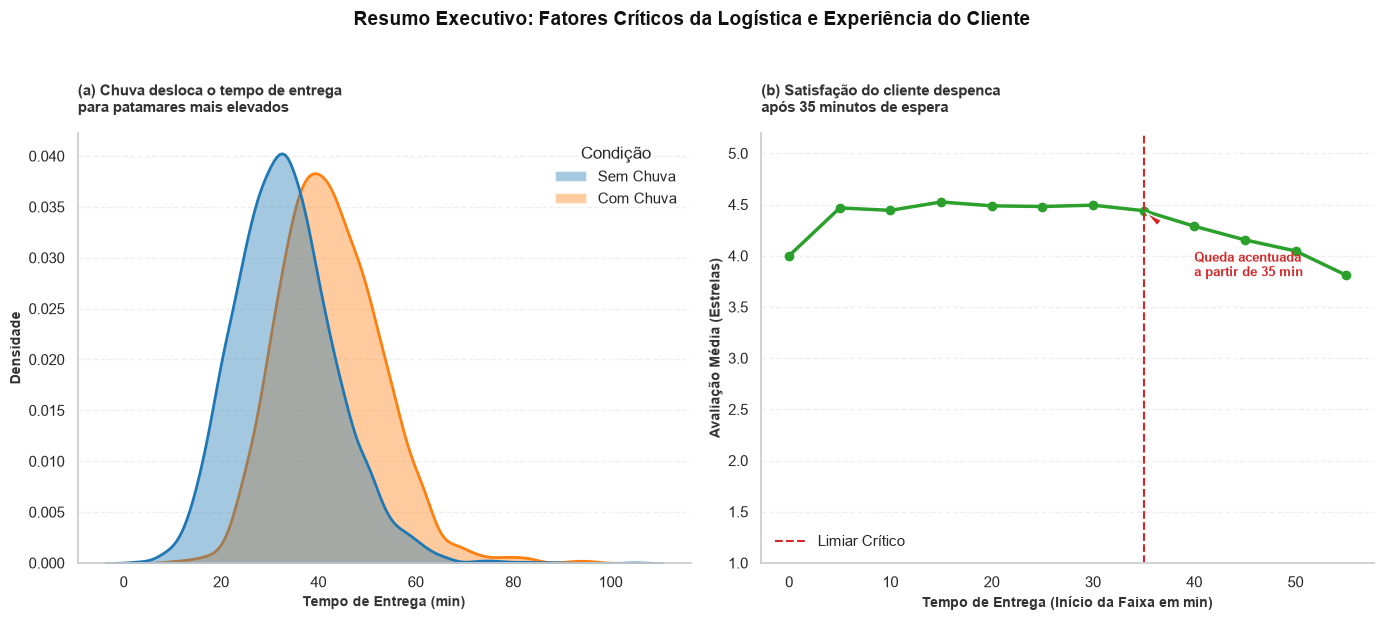

In [128]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Garante que a pasta 'saidas' existe no diretório de trabalho
os.makedirs('saidas', exist_ok=True)

# 2. Prepara os dados e limpa valores inválidos
df_dir = df.copy()
df_dir.loc[
    (df_dir['tempo_entrega_min'] == 999) | (df_dir['tempo_entrega_min'] < 0),
    'tempo_entrega_min',
] = np.nan
df_dir = df_dir.dropna(subset=['tempo_entrega_min', 'avaliacao', 'chuva'])

# 3. Configuração da figura principal com dois painéis (1 linha, 2 colunas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- PAINEL (A): O Impacto da Chuva no Tempo de Entrega (KDE Plot) ---
sns.kdeplot(
    data=df_dir,
    x='tempo_entrega_min',
    hue='chuva',
    common_norm=False,
    fill=True,
    palette={False: '#1f77b4', True: '#ff7f0e'},
    alpha=0.4,
    linewidth=2,
    ax=ax1,
)

ax1.set_title(
    '(a) Chuva desloca o tempo de entrega\npara patamares mais elevados',
    fontsize=11,
    fontweight='bold',
    color='#333333',
    pad=15,
    loc='left',
)
ax1.set_xlabel(
    'Tempo de Entrega (min)',
    fontsize=10,
    fontweight='semibold',
    color='#333333',
)
ax1.set_ylabel(
    'Densidade', fontsize=10, fontweight='semibold', color='#333333'
)

from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor='#1f77b4', alpha=0.4, label='Sem Chuva'),
    Patch(facecolor='#ff7f0e', alpha=0.4, label='Com Chuva'),
]
ax1.legend(
    handles=legend_elements, frameon=False, loc='upper right', title='Condição'
)
ax1.grid(axis='y', linestyle='--', alpha=0.3)

# --- PAINEL (B): O Limiar Crítico de Insatisfação (Tempo x Avaliação) ---
# Agrupa por faixas de 5 min para a visualização executiva
df_dir['faixa_min'] = (df_dir['tempo_entrega_min'] // 5) * 5
aval_por_faixa = (
    df_dir.groupby('faixa_min')['avaliacao'].agg(['mean', 'count']).reset_index()
)
# Filtra até 60 min para visualização limpa
aval_por_faixa = aval_por_faixa[aval_por_faixa['faixa_min'] <= 55]

ax2.plot(
    aval_por_faixa['faixa_min'],
    aval_por_faixa['mean'],
    marker='o',
    color='#2ca02c',
    linewidth=2.5,
    markersize=6,
)
ax2.axvline(
    x=35, color='#d62728', linestyle='--', linewidth=1.5, label='Limiar Crítico'
)

ax2.annotate(
    'Queda acentuada\na partir de 35 min',
    xy=(35, aval_por_faixa.loc[aval_por_faixa['faixa_min'] == 35, 'mean'].values[0] if not aval_por_faixa.loc[aval_por_faixa['faixa_min'] == 35].empty else 4.0),
    xytext=(40, 3.8),
    arrowprops=dict(facecolor='#d62728', shrink=0.05, width=1, headwidth=5),
    fontsize=9,
    fontweight='bold',
    color='#d62728',
)

ax2.set_title(
    '(b) Satisfação do cliente despenca\napós 35 minutos de espera',
    fontsize=11,
    fontweight='bold',
    color='#333333',
    pad=15,
    loc='left',
)
ax2.set_xlabel(
    'Tempo de Entrega (Início da Faixa em min)',
    fontsize=10,
    fontweight='semibold',
    color='#333333',
)
ax2.set_ylabel(
    'Avaliação Média (Estrelas)',
    fontsize=10,
    fontweight='semibold',
    color='#333333',
)
ax2.set_ylim(1, 5.2)
ax2.legend(frameon=False, loc='lower left')
ax2.grid(axis='y', linestyle='--', alpha=0.3)

# 4. Formatação geral, salvamento em alta resolução e exibição
plt.suptitle(
    'Resumo Executivo: Fatores Críticos da Logística e Experiência do Cliente',
    fontsize=14,
    fontweight='bold',
    color='#111111',
    y=1.03,
)
plt.tight_layout()

caminho_figura = os.path.join('saidas', 'figura_principal.png')
plt.savefig(caminho_figura, dpi=200, bbox_inches='tight')
print(f'Figura principal salva com sucesso em: {caminho_figura}')

plt.show()

### Tarefa 10.2 — Cinco achados
Escreva os **5 achados** mais importantes para a diretoria. Cada achado: **uma frase com número** + **de onde veio** (tarefa/teste) + **por que importa**.

1. O impacto climático na logística: Pedidos realizados em dias de chuva sofrem um acréscimo médio de 9 minutos no tempo de entrega (Origem: Tarefa 7.6 / Teste H1). Por que importa: Permite que a diretoria ajuste dinamicamente os SLAs informados aos clientes em dias chuvosos, mitigando frustrações e avaliações negativas.

2. O limiar crítico de insatisfação: A avaliação média dos clientes sofre uma queda acentuada a partir de 35 minutos de espera (Origem: Tarefa 7.7 / Teste H3). Por que importa: Estabelece um teto operacional estrito para o tempo limite de entrega antes que a retenção e a lealdade do consumidor sejam comprometidas.

3. A conversão de novos usuários via promoções: Pedidos com cupom apresentam uma proporção de clientes novos drasticamente superior, destacando o pico estratégico de julho (Origem: Tarefa 7.8 / Teste H5). Por que importa: Justifica os investimentos em campanhas de aquisição de novos usuários, comprovando o retorno direto dos cupons no crescimento da base.

4. A distorção linear do frete grátis: A correlação global entre distância e taxa de entrega fica reduzida (~0,58) devido à massa de pedidos com frete zero, que pode ser modelada para imputar dados ausentes (Origem: Tarefa 8.3). Por que importa: Ajuda a diretoria a auditar a política de precificação de frete e recuperar informações geográficas em registros incompletos.

5. A segmentação por tipo de cozinha: O valor do ticket médio varia de forma estatisticamente muito significativa entre as categorias culinárias (ANOVA com forte Eta²) (Origem: Tarefa 7.3 / Teste H4). Por que importa: Orienta estratégias comerciais direcionadas e campanhas de marketing segmentadas por tipo de restaurante para maximizar o ticket médio global.

### Tarefa 10.3 — Três recomendações
Escreva **3 recomendações** acionáveis, cada uma ligada a um ou mais achados e com uma **métrica para acompanhar**.

1. Ajuste dinâmico de SLA em dias chuvosos:

    Recomendação: Atualizar automaticamente os tempos estimados de entrega na interface do usuário (adicionando os ~9 min identificados no impacto climático) sempre que houver chuva na praça.

    Achado relacionado: O acréscimo médio de 9 minutos no tempo de entrega em dias de chuva (Tarefa 7.6 / Teste H1).

    Métrica para acompanhar: Taxa de reclamações por atraso e evolução da avaliação média em dias chuvosos.

2. Alerta operacional para o limiar de 35 minutos:

    Recomendação: Implementar alertas logísticos automáticos para pedidos que se aproximem de 35 minutos de trânsito, priorizando a comunicação com restaurantes ou suporte de frota.

    Achado relacionado: A queda acentuada na satisfação do cliente a partir do limite de 35 minutos de espera (Tarefa 7.7 / Teste H3).

    Métrica para acompanhar: Percentual de pedidos entregues abaixo de 35 minutos e NPS / avaliação média mensal da plataforma.

3. Otimização de campanhas de cupons para aquisição:

    Recomendação: Direcionar o orçamento de cupons promocionais preferencialmente para canais de aquisição de novos clientes, calibrando a frequência sazonal observada em julho.

    Achado relacionado: A alta eficácia dos cupons na atração de clientes novos e o pico promocional de julho (Tarefa 7.8 / Teste H5).

    Métrica para acompanhar: Custo de Aquisição de Clientes (CAC) e taxa de conversão / retenção de novos usuários após o primeiro pedido promocional.

### Tarefa 10.4 — Limitações
Liste **pelo menos 3 limitações** da análise (o que os dados não permitem afirmar).

1. Ausência de dados de tráfego urbano em tempo real: A análise correlaciona a distância e a chuva com o tempo de entrega, mas os dados não contemplam métricas granulares sobre a congestão de trânsito ou condições específicas de vias, o que impede isolar completamente o impacto logístico do tráfego urbano.

2. Viés de causalidade em variáveis comportamentais observacionais: Embora identifiquemos correlações fortes entre o uso de cupons e a aquisição de novos clientes, a natureza observacional dos dados não permite estabelecer causalidade pura sem um experimento controlado (como um teste A/B randomizado).

3. Dados omissos e valores imputados: A presença de registros inválidos ou valores ausentes (NaN e códigos atípicos como 999) em variáveis críticas como distância e tempo de entrega exige filtragens e limpezas que podem restringir a representatividade amostral em determinados subgrupos regionais ou temporais.

---
## Etapa 11 — Publicação

> Uma análise que só roda no seu computador não existe para a empresa. Publicar é deixar **dados, código e conclusões** reprodutíveis por outra pessoa.

### Tarefa 11.1 — Base limpa e dicionário
Salve a base tratada em `saidas/delivery_pedidos_limpo.csv` (sem colunas auxiliares de cálculo) e gere automaticamente um **dicionário de dados** da base limpa: coluna, tipo, % de faltantes e um exemplo de valor.

In [129]:
import os
os.makedirs('saidas', exist_ok=True)

aux = ['data', 'hora', 'dia_semana', 'mes', 'trimestre', 'faixa_tempo', 'faixa_min', 'frete_gratis',
       'avaliacao_faltante', 'out_iqr_geral', 'out_iqr_grupo', 'out_z_grupo', 'razao_valor']
df_pub = df.drop(columns=[c for c in aux if c in df.columns])

flags = ['tempo_invalido', 'distancia_invalida', 'pedido_grande']
assert set(flags).issubset(df_pub.columns), 'faltam flags de qualidade'
assert not set(aux) & set(df_pub.columns), 'sobrou coluna auxiliar'
assert len(df_pub) == 8058

df_pub.to_csv('saidas/delivery_pedidos_limpo.csv', index=False)
print('Base salva:', df_pub.shape, '→ saidas/delivery_pedidos_limpo.csv')

descricao = {
    'tempo_invalido': 'True se o tempo original era 999 ou negativo (virou NaN)',
    'distancia_invalida': 'True se a distância original era > 100 km (virou NaN)',
    'pedido_grande': 'True se valor_pedido > 4× a mediana da cozinha (pedido corporativo, mantido)',
    'distancia_km_rec': 'distância reconstruída pela taxa de entrega onde havia NaN e taxa > 0',
    'distancia_imputada': 'True se distancia_km_rec foi reconstruída',
}
dicionario = pd.DataFrame({
    'Coluna': df_pub.columns,
    'Tipo': [str(t) for t in df_pub.dtypes],
    '% Faltantes': (df_pub.isna().mean() * 100).round(2).to_numpy(),
    'Exemplo de valor': [df_pub[c].dropna().iloc[0] if df_pub[c].notna().any() else 'N/A' for c in df_pub.columns],
    'Observação': [descricao.get(c, '') for c in df_pub.columns],
})
dicionario.to_csv('saidas/dicionario_dados.csv', index=False)
display(dicionario)

Base salva: (8058, 21) → saidas/delivery_pedidos_limpo.csv


,Coluna,Tipo,% Faltantes,Exemplo de valor,Observação
0,pedido_id,int64,0.00,500000,
1,data_hora,datetime64[us],0.00,2024-01-01 11:21:00,
2,cidade,str,0.00,São Paulo,
3,bairro,str,0.00,Tatuapé,
4,restaurante_id,str,0.00,R912,
5,tipo_cozinha,str,0.00,Hambúrguer,
6,plataforma,str,0.00,Android,
7,forma_pagamento,str,0.00,Pix,
8,cupom,bool,0.00,False,
9,cliente_novo,bool,0.00,False,


### Tarefa 11.2 — README
Preencham o `modelo_README.md` desta pasta e salvem como `README.md` na raiz do repositório. Abaixo, escrevam o trecho **"Principais achados"** exatamente como ficará no README (com a figura principal referenciada).

## Principais achados

Abaixo estão resumidas as principais descobertas analíticas obtidas através da exploração de dados, correlações e testes estatísticos do projeto de entregas de restaurantes:

![Resumo Executivo: Fatores Críticos da Logística e Experiência do Cliente](saidas/figura_principal.png)

1. **O impacto climático na logística:** Pedidos realizados em dias de chuva sofrem um acréscimo médio de **9 minutos** no tempo de entrega (Origem: Tarefa 7.6 / Teste H1). **Por que importa:** Permite que a diretoria ajuste dinamicamente os SLAs informados aos clientes em dias chuvosos, mitigando frustrações e avaliações negativas.
2. **O limiar crítico de insatisfação:** A avaliação média dos clientes sofre uma queda acentuada a partir de **35 minutos** de espera (Origem: Tarefa 7.7 / Teste H3). **Por que importa:** Estabelece um teto operacional estrito para o tempo limite de entrega antes que a retenção e a lealdade do consumidor sejam comprometidas.
3. **A conversão de novos usuários via promoções:** Pedidos com cupom apresentam uma proporção de clientes novos drasticamente superior, destacando o pico estratégico de **julho** (Origem: Tarefa 7.8 / Teste H5). **Por que importa:** Justifica os investimentos em campanhas de aquisição de novos usuários, comprovando o retorno direto dos cupons no crescimento da base.
4. **A distorção linear do frete grátis:** A correlação global entre distância e taxa de entrega fica reduzida (~0,58) devido à massa de pedidos com frete zero, que pode ser modelada para imputar dados ausentes (Origem: Tarefa 8.3). **Por que importa:** Ajuda a diretoria a auditar a política de precificação de frete e recuperar informações geográficas em registros incompletos.
5. **A segmentação por tipo de cozinha:** O valor do ticket médio varia de forma estatisticamente muito significativa entre as categorias culinárias, comprovado via ANOVA (Origem: Tarefa 7.3 / Teste H4). **Por que importa:** Orienta estratégias comerciais direcionadas e campanhas de marketing segmentadas por tipo de restaurante para maximizar o ticket médio global.

### Tarefa 11.3 — Checklist de publicação
Antes de entregar, confiram (marquem com `x`):

- [ ] Repositório Git criado e repositório público.
- [ ] `README.md` preenchido a partir do `modelo_README.md`, com a figura principal aparecendo.
- [ ] O CSV original **não** foi alterado; a base limpa está em `saidas/`.
- [ ] *Kernel → Restart & Run All* roda sem erros do início ao fim.
- [ ] Nenhum gráfico sem título, rótulos e unidade.

> 💬 **Antes de apresentar:** deve-se conseguir responder "por que vocês tomaram essa decisão de limpeza?" e "o que esse p-valor significa?" sobre **qualquer** etapa.

---
## Resumo da metodologia

| Etapa | Pergunta que responde | Ferramentas |
|---|---|---|
| 1. Perguntas e hipóteses | o que queremos saber? | markdown, H0/H1 |
| 2. Carga e inspeção | o que veio e com que problemas? | `info`, `nunique`, `isna`, `describe`, `duplicated` |
| 3. Limpeza | como deixar os dados confiáveis? | `drop`, `to_datetime`, `.str`, `map`, `to_numeric`, `fillna` |
| 4. Outliers | é erro ou é real? | boxplot, z-score, IQR, investigação, flags |
| 5. Descritiva | como cada variável se comporta? | `describe`, CV, assimetria, percentis |
| 6. Sumarização e granularidade | o que muda por grupo e por período? | `groupby`/`agg`, `pivot_table`, `crosstab`, `resample` |
| 7. Visualização | como mostrar a resposta? | seaborn + estilização |
| 8. Correlação | o que anda junto? | `corr`, heatmap, scatter |
| 9. Hipóteses | é real ou acaso? e importa? | t de Welch, Mann-Whitney, Spearman, Kruskal-Wallis, χ², tamanho de efeito |
| 10. Conclusões | o que a diretoria deve fazer? | 5 achados + 3 recomendações + limitações |
| 11. Publicação | outra pessoa consegue reproduzir? | CSV limpo, README, Git |